# QMSS5074GR: Projects in Advanced Machine Learning
## Project 1: World Happiness Classification

**Group number:** 6

| Full Name | UNI |
|---|---|
| Changyang Zhu | |
| Yizhang Mu | |

**Public GitHub repository URL:**

**GitHub account:** https://github.com/deepthink869

## Submission and reproducibility

**Due: Monday, October 19, 2026.** Complete the UNI fields and public **repository** URL above before submission.

- **Canvas:** one group member submits `Project_1.ipynb`, including saved code, tables, figures and answers.
- **GitHub:** the same Notebook belongs at `Project_1/Project_1.ipynb`; the supplied CSVs belong in `Project_1/data/`. The repository must be public and accessible in a signed-out/private window.
- **Run:** open this Notebook with `data/` alongside it, then select **Restart Kernel and Run All Cells**. Save the completed run. `requirements.txt` records the tested package versions; the setup cell also reports the environment actually used.
- Result-dependent discussions are generated from computed objects. A new run can change model rankings, especially for the small neural validation set; the explanations and final table update with those results.

The source data are the two CSVs supplied with this assignment. The methods follow the assignment's scikit-learn/Keras workflow; no additional course handouts are needed to reproduce this analysis.

## About the Project

### What this project is about

Why are people in some countries happier than in others? Every year, the **World Happiness Report** surveys people around the world (through the Gallup World Poll) and asks them to rate their current life on a ladder from **0 (worst possible life)** to **10 (best possible life)**. A country's happiness score is the average of these answers.

In this project, you will build models that **predict how happy a country is from its economic, social, and development indicators**, and then look inside those models to see which factors matter most. Along the way, you will practice the full machine learning workflow: merging datasets, exploring data, engineering features, building a preprocessing pipeline, training and tuning classical models, training a neural network, and explaining predictions with SHAP.

### The prediction task

This is a **multi-class classification** problem. In Section 0, the numeric `happiness_score` is split into **five equal-sized groups** (quintiles) of about 27 countries each:

**Very Low → Low → Average → High → Very High**

Your models predict which group each country belongs to. With only **137 countries** (95 for training, 42 for testing), this is a small dataset, so keep that in mind when you interpret your results.

---

### The data

You will work with two files, both in the `data` folder.

#### 1. `WHR_2023.csv`: World Happiness Report 2023 (137 countries)

| Column | What it means |
|--------|---------------|
| `country` | Country name (used to merge with the second file) |
| `region` | World region (10 regions, e.g., *Western Europe*, *Sub-Saharan Africa*) |
| `happiness_score` | Average life rating on the 0–10 ladder, from surveys in 2020–2022. **Used only to create the target, not as a feature.** |
| `gdp_per_capita` | Contribution of economic output per person |
| `social_support` | Contribution of having someone to count on in times of trouble |
| `healthy_life_expectancy` | Contribution of the number of years people live in good health |
| `freedom_to_make_life_choices` | Contribution of people's satisfaction with their freedom to choose what to do with their lives |
| `generosity` | Contribution of donating to charity (adjusted for income) |
| `perceptions_of_corruption` | Contribution of how widespread people think corruption is in government and business |

> **Important:** The six factor columns are **not** raw measurements. The World Happiness Report estimates how much each factor adds to a country's happiness score compared with *"Dystopia"*, an imaginary country with the world's lowest value of every factor. They are measured in **happiness-score points**. For example, Finland's `healthy_life_expectancy` is 0.535: health adds about half a point to Finland's score. It does *not* mean a life expectancy of 0.535 years.

#### 2. `newcountryvars.csv`: Country development indicators (174 countries)

| Column | What it means |
|--------|---------------|
| `country_name` | Country name (used to merge with the first file) |
| `population` | Total population |
| `population_below_poverty_line` | Percentage of people living below the national poverty line |
| `hdi` | Human Development Index (0–1): the UN's summary measure of health, education, and income |
| `life_expectancy` | Life expectancy at birth, in years |
| `expected_years_of_schooling` | Years of schooling a child starting school can expect to receive |
| `mean_years_of_schooling` | Average years of schooling completed by adults aged 25 and older |
| `gni` | Gross National Income per person, in international dollars adjusted for cost of living (PPP) |

These indicators come from roughly **2015–2017**, a few years earlier than the happiness surveys, and some values are missing.

#### Combining the two files

In Section 0, you will merge the second file into the first using `country` and `country_name`. Not every country appears in both files, and some countries are spelled differently, so check the merge carefully.

### Analysis plan

We retain the assignment's 95-country training / 42-country test split. EDA and preprocessing decisions use training data. Random Forest tuning fits preprocessing separately inside each cross-validation fold. Neural networks use a separate stratified 71-country fitting / 24-country validation split, with preprocessing learned only from the 71 fitting countries.

Validation results select hyperparameters and neural variants. After these decisions are fixed, the final section reports test performance for **every fitted experimental configuration**. Those test results are descriptive comparisons, not an invitation to retune. The 42-country test sample is too small to establish superiority from one or two extra correct predictions.

---

## 0. Loading Datasets

In this section, we load the two datasets described above, `WHR_2023.csv` and `newcountryvars.csv`, create the target variable, split the data into training and test sets, and merge in the extra country indicators.

**Objectives of this stage:**

- Import the datasets into the notebook environment
- Inspect their structure and contents
- Verify column names and data types
- Identify potential inconsistencies before merging

> Careful dataset inspection at this stage prevents downstream errors and ensures a clean modeling pipeline.

In [1]:
# Install missing dependencies at the tested versions. Existing versions are reported below.
import importlib.util, importlib.metadata, subprocess, sys
TESTED = {
    'pandas': ('pandas', '3.0.6'), 'numpy': ('numpy', '2.5.4'),
    'sklearn': ('scikit-learn', '1.9.1'), 'scipy': ('scipy', '1.18.1'),
    'matplotlib': ('matplotlib', '3.11.2'), 'seaborn': ('seaborn', '0.13.2'),
    'keras': ('keras', '3.15.1'), 'torch': ('torch', '2.14.1'),
    'shap': ('shap', '0.54.1'), 'joblib': ('joblib', '1.6.0'),
}
missing = [f'{package}=={version}' for module, (package, version) in TESTED.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Dependencies available. For the tested environment: pip install -r requirements.txt')

Dependencies available. For the tested environment: pip install -r requirements.txt


In [2]:
import os
os.environ['KERAS_BACKEND'] = 'torch'
os.environ['OMP_NUM_THREADS'] = '1'
import random, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 115, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.facecolor': 'white',
                     'axes.prop_cycle': plt.cycler(color=['#2463A0','#D18B20','#7652A1','#278477','#B4516B'])})
def explain(text):
    display(Markdown(text))

environment = pd.DataFrame([
    {'Package': package, 'Installed': importlib.metadata.version(package), 'Tested': version}
    for package, version in TESTED.values()])
print('Python:', platform.python_version(), '| Platform:', platform.system(), '| Keras backend: torch (CPU)')
display(environment)
if (environment['Installed'] != environment['Tested']).any():
    print('Version differences detected: use requirements.txt for the tested versions; results may differ.')
print('Seeds and deterministic CPU operations reduce variability; cross-version identity is not guaranteed.')
whr_df = pd.read_csv('data/WHR_2023.csv')
assert len(whr_df) == 137 and whr_df['country'].is_unique
print('WHR shape:', whr_df.shape)
display(whr_df.head())

Python: 3.12.14 | Platform: Darwin | Keras backend: torch (CPU)


,Package,Installed,Tested
0,pandas,3.0.6,3.0.6
1,numpy,2.5.4,2.5.4
2,scikit-learn,1.9.1,1.9.1
3,scipy,1.18.1,1.18.1
4,matplotlib,3.11.2,3.11.2
5,seaborn,0.13.2,0.13.2
6,keras,3.15.1,3.15.1
7,torch,2.14.1,2.14.1
8,shap,0.54.1,0.54.1
9,joblib,1.6.0,1.6.0


Seeds and deterministic CPU operations reduce variability; cross-version identity is not guaranteed.
WHR shape: (137, 9)


,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption
0,Finland,Western Europe,7.804,1.888,1.585,0.535,0.772,0.126,0.535
1,Denmark,Western Europe,7.586,1.949,1.548,0.537,0.734,0.208,0.525
2,Iceland,Western Europe,7.530,1.926,1.620,0.559,0.738,0.250,0.187
3,Israel,Middle East and North Africa,7.473,1.833,1.521,0.577,0.569,0.124,0.158
4,Netherlands,Western Europe,7.403,1.942,1.488,0.545,0.672,0.251,0.394


In [3]:
# Split the original 137 observations into five equal-frequency classes.
CLASS_NAMES = ['Very Low', 'Low', 'Average', 'High', 'Very High']
whr_df['happiness_category'] = pd.qcut(whr_df['happiness_score'], q=5, labels=CLASS_NAMES)
X = whr_df.drop(columns=['happiness_score', 'happiness_category'])
y = whr_df['happiness_category']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
y_train_labels = y_train.astype('category').cat.codes
y_test_labels = y_test.astype('category').cat.codes
print('Rows: train', len(y_train), '| test', len(y_test))
print('Training class counts:', y_train.value_counts(sort=False).to_dict())
print('Encoded target labels:', dict(enumerate(CLASS_NAMES)))

Rows: train 95 | test 42
Training class counts: {'Very Low': 19, 'Low': 19, 'Average': 19, 'High': 19, 'Very High': 19}
Encoded target labels: {0: 'Very Low', 1: 'Low', 2: 'Average', 3: 'High', 4: 'Very High'}


### Conceptual Question

In the next cell, briefly explain the following:

1. What does `y_train.astype('category').cat.codes` do?
2. What is the difference between `y_train_labels` and `y_train`?

Keep your explanation clear and concise.

1. `astype('category')` represents `y_train` as categorical data; `.cat.codes` converts the five *ordered* categories into integers 0–4, following the category order: Very Low, Low, Average, High, Very High.
2. `y_train` contains human-readable category labels, whereas `y_train_labels` contains numerical class IDs for classifiers. Both encode the same outcomes in the same row order; the labels differ in representation, not meaning. The test labels are encoded identically.

### Add New Data

In [4]:
countrydata = pd.read_csv('data/newcountryvars.csv')
print('Development dataset shape:', countrydata.shape)
display(countrydata.head())

# Make clear, exact equivalences for the known naming differences.
name_map = {
    'Congo': 'Congo (Brazzaville)',
    'Democratic Republic of the Congo': 'Congo (Kinshasa)',
    'Czech Republic': 'Czechia',
    'Hong Kong': 'Hong Kong S.A.R. of China',
    'Macedonia': 'North Macedonia',
    'Palestine': 'State of Palestine',
    'Turkey': 'Turkiye',
    'VietNam': 'Vietnam',
}
countrydata['country_name'] = countrydata['country_name'].replace(name_map)

common_countries = set(X['country']) & set(countrydata['country_name'])
unmatched = sorted(set(X['country']) - common_countries)
print(f'Exact/harmonized country matches: {len(common_countries)}/{len(X)}')
print('Countries without development records:', unmatched)
print('Duplicate country names in development data:', countrydata['country_name'].duplicated().sum())

Development dataset shape: (174, 8)


,country_name,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,India,1339180127,21.9,0.623559,68.322,11.696590,6.298834,5663.474799
1,Nigeria,190886311,70.0,0.527105,53.057,9.970482,6.000000,5442.901264
2,Mexico,129163276,46.2,0.761683,76.972,13.299090,8.554985,16383.106680
3,Pakistan,197015955,29.5,0.550354,66.365,8.106910,5.089460,5031.173074
4,Bangladesh,164669751,31.5,0.578824,71.985,10.178706,5.241577,3341.490722


Exact/harmonized country matches: 136/137
Countries without development records: ['Taiwan Province of China']
Duplicate country names in development data: 0


In [5]:
# Left join preserves every WHR observation and the target-label row order.
train_country_order = X_train['country'].tolist()
test_country_order = X_test['country'].tolist()
# Reset indexes because sklearn models depend on row order, not DataFrame index labels.
X_train = (X_train.merge(countrydata, how='left', left_on='country',
                         right_on='country_name', sort=False, validate='one_to_one')
           .drop(columns='country_name').reset_index(drop=True))
X_test = (X_test.merge(countrydata, how='left', left_on='country',
                       right_on='country_name', sort=False, validate='one_to_one')
          .drop(columns='country_name').reset_index(drop=True))
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
assert not X_train['country'].duplicated().any()
print('Merged train:', X_train.shape, '| test:', X_test.shape)
print('Country with no matched development data:', unmatched)
assert X_train['country'].tolist() == train_country_order
assert X_test['country'].tolist() == test_country_order

Merged train: (95, 15) | test: (42, 15)
Country with no matched development data: ['Taiwan Province of China']


In [6]:
X_train.head(1)

,country,region,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,Madagascar,Sub-Saharan Africa,0.632,0.779,0.178,0.187,0.177,0.134,25570895.0,70.7,0.512149,65.515,10.34614,6.145955,1319.699397


---

## 1. Exploratory Data Analysis and Visualization (EDAV)

In [7]:
print(X_train.dtypes)

country                              str
region                               str
gdp_per_capita                   float64
social_support                   float64
healthy_life_expectancy          float64
freedom_to_make_life_choices     float64
generosity                       float64
perceptions_of_corruption        float64
population                       float64
population_below_poverty_line    float64
hdi                              float64
life_expectancy                  float64
expected_years_of_schooling      float64
mean_years_of_schooling          float64
gni                              float64
dtype: object


### Describe What You Observe

`country` and `region` are string/object columns; the remaining columns are numerical indicators (mostly floats, with population possibly stored as an integer/float). Country is an identifier, so we **exclude it from predictors**; region is a nominal categorical predictor and needs one-hot encoding. Numerical scales differ widely (e.g., population versus HDI), and missing development data must be imputed. We use a **left join** so the 95 training/42 test countries and their labels remain aligned. After harmonizing eight names, 136/137 WHR countries have a matching country record; Taiwan Province of China has no corresponding row in this development file.

### Missing Values Analysis

Compute the number and percentage of missing values for each column and present the results in a clear summary table.

In [8]:
missing_summary = pd.DataFrame({
    'missing_n': X_train.isna().sum(),
    'missing_pct': (100 * X_train.isna().mean()).round(1),
}).sort_values(['missing_n', 'missing_pct'], ascending=False)
print('Missing values in training data (n=95):')
display(missing_summary)
print('Test missingness (shown for diagnostics, not used to fit preprocessing):')
display(pd.DataFrame({'missing_n': X_test.isna().sum(),
                      'missing_pct': (100 * X_test.isna().mean()).round(1)}))

Missing values in training data (n=95):


,missing_n,missing_pct
population_below_poverty_line,11,11.6
life_expectancy,2,2.1
expected_years_of_schooling,2,2.1
mean_years_of_schooling,2,2.1
gni,2,2.1
population,1,1.1
hdi,1,1.1
country,0,0.0
region,0,0.0
gdp_per_capita,0,0.0


Test missingness (shown for diagnostics, not used to fit preprocessing):


,missing_n,missing_pct
country,0,0.0
region,0,0.0
gdp_per_capita,0,0.0
social_support,0,0.0
healthy_life_expectancy,1,2.4
freedom_to_make_life_choices,0,0.0
generosity,0,0.0
perceptions_of_corruption,0,0.0
population,0,0.0
population_below_poverty_line,1,2.4


### Distribution of Key Numerical Features

Select relevant numerical features and plot their histograms. Choose features that may influence the target variable, and briefly comment on notable patterns, skewness, or outliers.

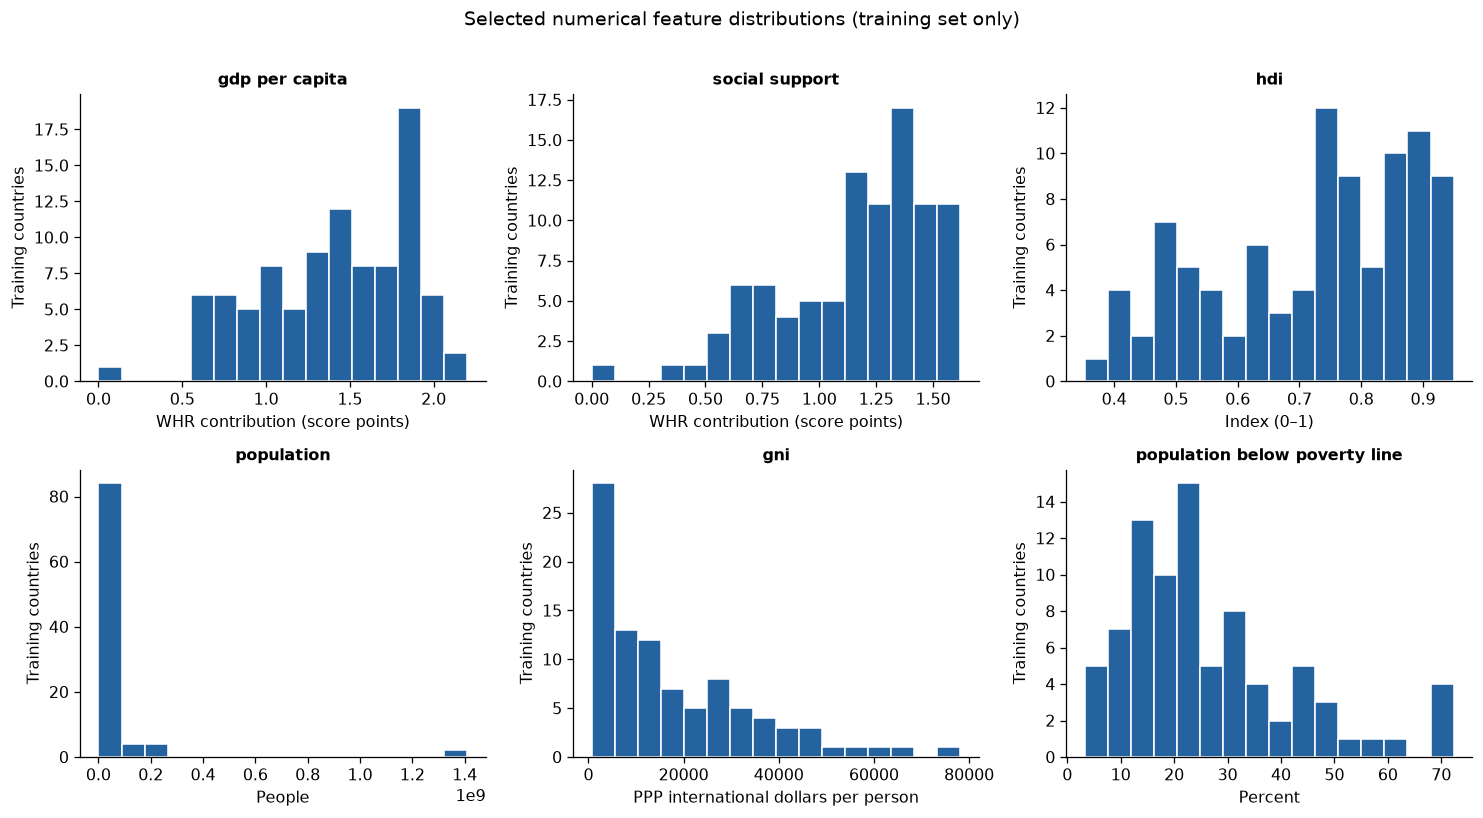

,skewness
gdp_per_capita,-0.55
social_support,-0.95
hdi,-0.50
population,6.21
gni,1.24
population_below_poverty_line,1.15


Population and GNI have strong right tails; log1p transformations will be added.


In [9]:
num_columns = X_train.select_dtypes(include='number').columns.tolist()
plot_vars = ['gdp_per_capita', 'social_support', 'hdi', 'population', 'gni',
             'population_below_poverty_line']
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axs.flat, plot_vars):
    ax.hist(X_train[col].dropna(), bins=16, edgecolor='white')
    ax.set_title(col.replace('_', ' '), fontsize=10)
    ax.set_ylabel('Training countries')
    ax.set_xlabel({'population': 'People', 'gni': 'PPP international dollars per person',
                   'hdi': 'Index (0–1)', 'population_below_poverty_line': 'Percent',
                   'gdp_per_capita': 'WHR contribution (score points)',
                   'social_support': 'WHR contribution (score points)'}[col])
fig.suptitle('Selected numerical feature distributions (training set only)', y=1.01)
plt.tight_layout(); plt.show()
skew_table = X_train[plot_vars].skew().rename('skewness').to_frame().round(2)
display(skew_table)
print('Population and GNI have strong right tails; log1p transformations will be added.')

### Distribution of Categorical Variables

Plot the distribution of relevant categorical variables using appropriate visualizations (e.g., count plots or bar charts). Briefly comment on class imbalance or notable patterns.

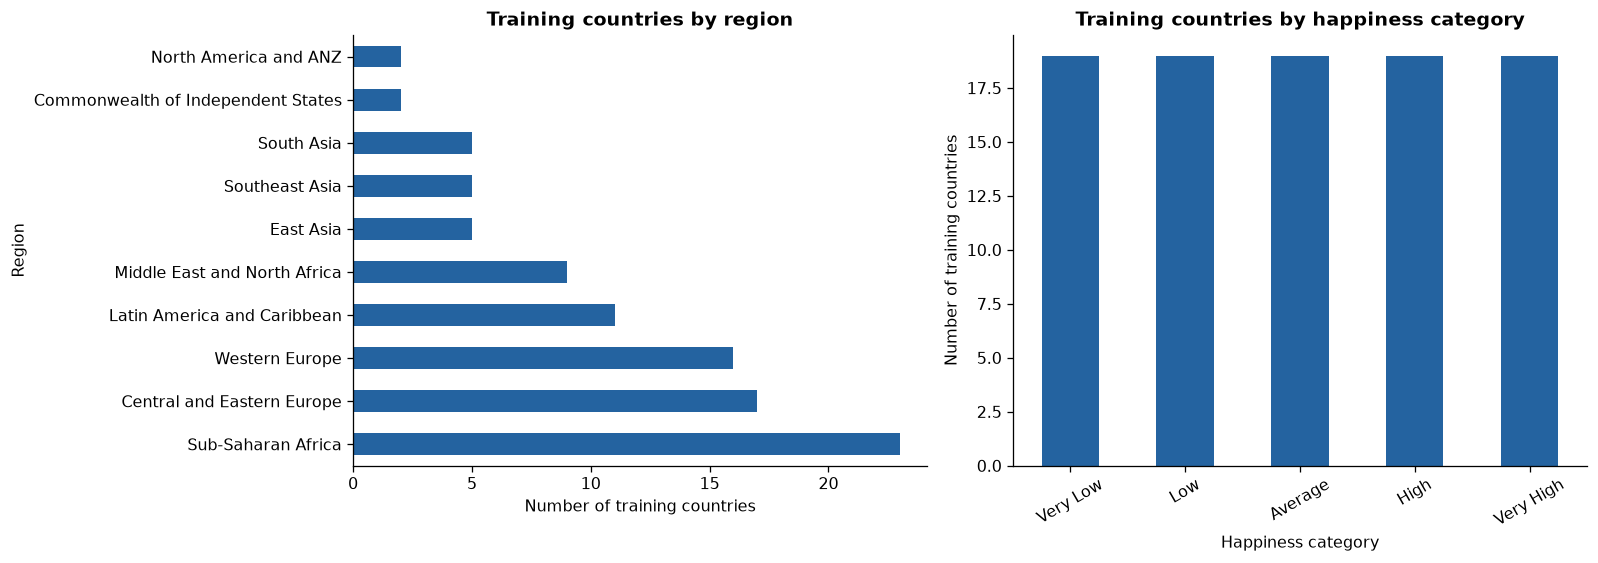

Targets are balanced in train (19 per category) by stratified splitting.
Regions are NOT balanced; the smallest have just two countries.


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
X_train['region'].value_counts().plot(kind='barh', ax=axs[0], title='Training countries by region')
pd.Series(y_train.to_numpy(), name='happiness_category').value_counts().reindex(CLASS_NAMES).plot(
    kind='bar', ax=axs[1], title='Training countries by happiness category')
axs[1].tick_params(axis='x', rotation=30)
axs[0].set(xlabel='Number of training countries', ylabel='Region')
axs[1].set(xlabel='Happiness category', ylabel='Number of training countries')
plt.tight_layout(); plt.show()
print('Targets are balanced in train (19 per category) by stratified splitting.')
print('Regions are NOT balanced; the smallest have just two countries.')

### Feature Correlation Analysis

Analyze the relationships between numerical features using correlation coefficients. Compute and visualize:

- **Pearson correlation** — linear relationships
- **Spearman correlation** — monotonic relationships
- **Kendall correlation** — rank-based relationships

Use correlation matrices and heatmaps where appropriate. Briefly interpret strong positive or negative correlations and discuss potential multicollinearity.

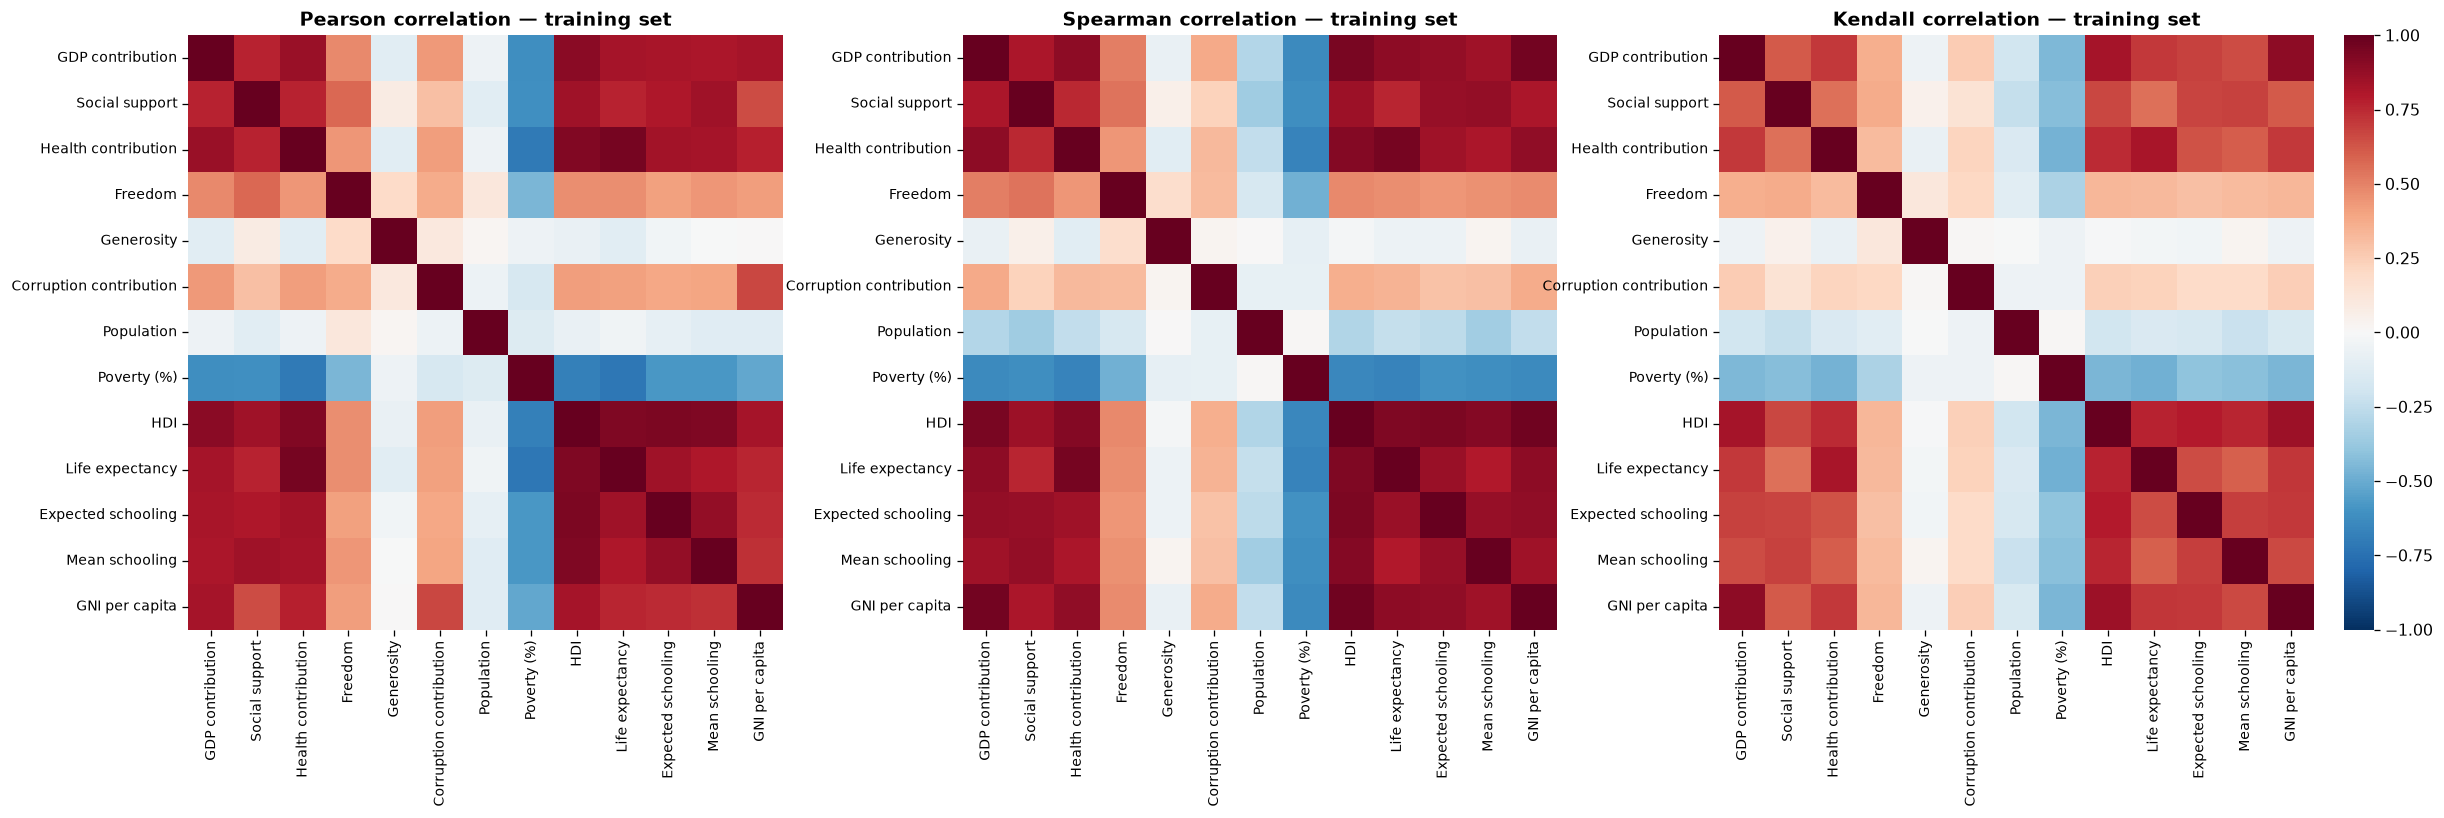

,feature_1,feature_2,Pearson r,abs_r
35,healthy_life_expectancy,life_expectancy,0.958,0.958
114,hdi,expected_years_of_schooling,0.938,0.938
115,hdi,mean_years_of_schooling,0.934,0.934
113,hdi,life_expectancy,0.932,0.932
34,healthy_life_expectancy,hdi,0.927,0.927
8,gdp_per_capita,hdi,0.904,0.904
141,expected_years_of_schooling,mean_years_of_schooling,0.880,0.880
2,gdp_per_capita,healthy_life_expectancy,0.860,0.860
21,social_support,hdi,0.850,0.850
127,life_expectancy,expected_years_of_schooling,0.848,0.848


**Interpretation.** HDI correlates strongly with expected schooling
(Pearson r = 0.938)
and life expectancy (r = 0.932).
The rank-based matrices show whether those associations also hold monotonically;
Kendall coefficients have a different scale and need not equal Pearson or Spearman.
These overlapping development measures create multicollinearity: importance can be
shared across substitutes, so a low individual attribution does not prove irrelevance.

In [11]:
import seaborn as sns
corr_matrices = {method: X_train[num_columns].corr(method=method)
                 for method in ('pearson', 'spearman', 'kendall')}
short_labels = {'gdp_per_capita':'GDP contribution','social_support':'Social support',
    'healthy_life_expectancy':'Health contribution','freedom_to_make_life_choices':'Freedom',
    'generosity':'Generosity','perceptions_of_corruption':'Corruption contribution',
    'population':'Population','population_below_poverty_line':'Poverty (%)','hdi':'HDI',
    'life_expectancy':'Life expectancy','expected_years_of_schooling':'Expected schooling',
    'mean_years_of_schooling':'Mean schooling','gni':'GNI per capita'}
fig, axes = plt.subplots(1, 3, figsize=(21, 7), layout='constrained')
for ax, (method, matrix) in zip(axes, corr_matrices.items()):
    labelled = matrix.rename(index=short_labels, columns=short_labels)
    sns.heatmap(labelled, vmin=-1, vmax=1, cmap='RdBu_r', center=0,
                square=True, cbar=(method == 'kendall'), ax=ax)
    ax.set_title(f'{method.title()} correlation — training set')
    ax.tick_params(labelsize=9)
plt.show()
pearson_pairs = (corr_matrices['pearson'].where(
    np.triu(np.ones(corr_matrices['pearson'].shape), k=1).astype(bool))
    .stack().rename('Pearson r').reset_index().rename(
        columns={'level_0':'feature_1','level_1':'feature_2'}))
pearson_pairs['abs_r'] = pearson_pairs['Pearson r'].abs()
display(pearson_pairs.sort_values('abs_r', ascending=False).head(10).round(3))
explain(f"""**Interpretation.** HDI correlates strongly with expected schooling
(Pearson r = {corr_matrices['pearson'].loc['hdi','expected_years_of_schooling']:.3f})
and life expectancy (r = {corr_matrices['pearson'].loc['hdi','life_expectancy']:.3f}).
The rank-based matrices show whether those associations also hold monotonically;
Kendall coefficients have a different scale and need not equal Pearson or Spearman.
These overlapping development measures create multicollinearity: importance can be
shared across substitutes, so a low individual attribution does not prove irrelevance.""")

### Bivariate Analysis and Relationship Exploration

Explore relationships between features and examine how they associate with the target variable. Include:

- Bivariate plots (e.g., scatter plots, box plots, grouped bar charts)
- Correlation tables
- Comparisons of feature distributions across target classes

Briefly summarize key relationships and any patterns that may influence model performance.

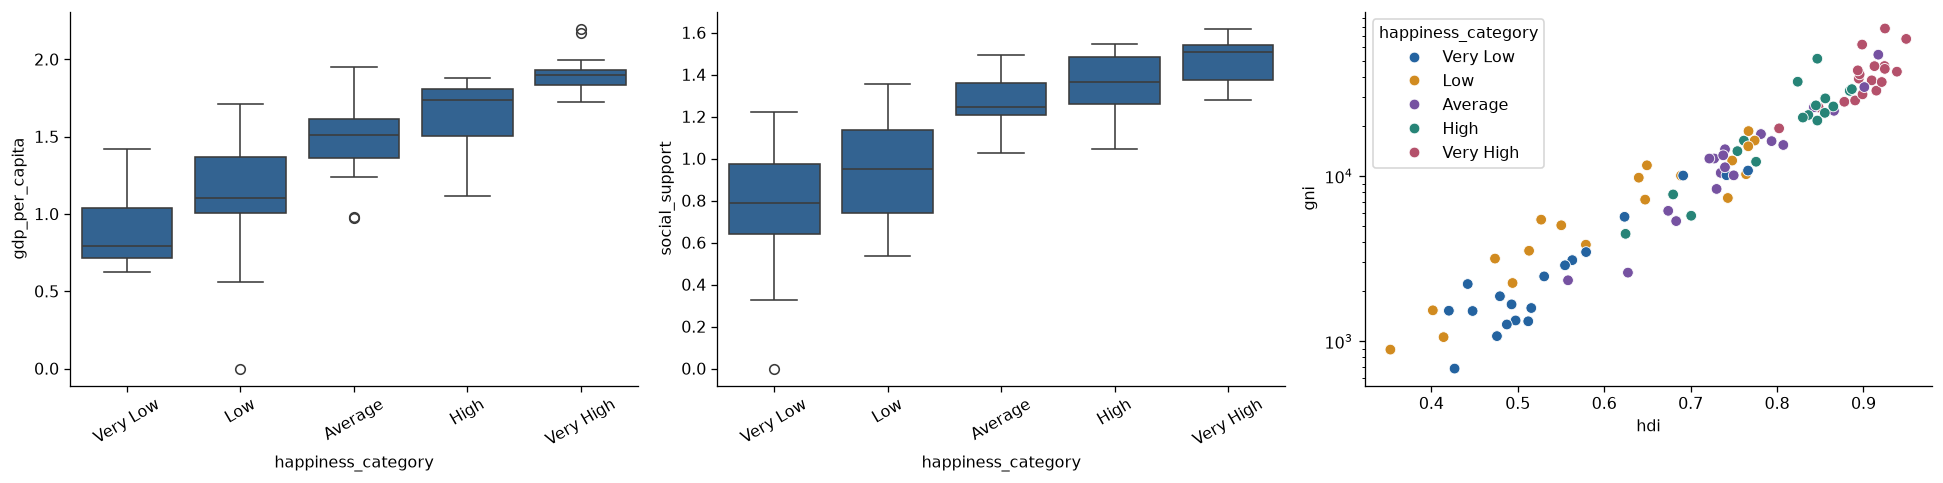

,gdp_per_capita,social_support,hdi,life_expectancy
happiness_category,,,,
Very Low,0.898,0.769,0.539,63.895
Low,1.117,0.920,0.605,66.913
Average,1.480,1.277,0.754,75.455
High,1.633,1.349,0.806,76.875
Very High,1.911,1.473,0.901,80.734


,Spearman correlation with happiness class
gdp_per_capita,0.841
social_support,0.836
hdi,0.828
gni,0.825
mean_years_of_schooling,0.785
expected_years_of_schooling,0.781
life_expectancy,0.773
healthy_life_expectancy,0.757
freedom_to_make_life_choices,0.614
perceptions_of_corruption,0.362


Associations describe the training data only and do not imply causation.


In [12]:
# Country-level rows must stay in their original shuffled order when attaching labels.
eda_train = X_train.assign(happiness_category=y_train.to_numpy(),
                           target_rank=y_train_labels.to_numpy())
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
sns.boxplot(data=eda_train, x='happiness_category', y='gdp_per_capita',
            order=CLASS_NAMES, ax=axes[0])
sns.boxplot(data=eda_train, x='happiness_category', y='social_support',
            order=CLASS_NAMES, ax=axes[1])
sns.scatterplot(data=eda_train, x='hdi', y='gni',
                hue='happiness_category', hue_order=CLASS_NAMES, ax=axes[2], s=45)
axes[2].set_yscale('log')
for ax in axes[:2]: ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
class_means = eda_train.groupby('happiness_category', observed=False)[
    ['gdp_per_capita', 'social_support', 'hdi', 'life_expectancy']].mean().reindex(CLASS_NAMES)
display(class_means.round(3))
association = eda_train[num_columns + ['target_rank']].corr(method='spearman')[
    'target_rank'].drop('target_rank').sort_values(ascending=False)
display(association.rename('Spearman correlation with happiness class').round(3).to_frame())
print('Associations describe the training data only and do not imply causation.')

### Outlier Detection

Identify potential outliers in the numerical features using appropriate methods such as:

- Box plots
- Z-score analysis
- Interquartile Range (IQR) method

Highlight any significant anomalies and briefly comment on whether they should be retained, transformed, or removed.

,IQR flags
perceptions_of_corruption,10
population,10
population_below_poverty_line,5
freedom_to_make_life_choices,3
social_support,2
gni,2
gdp_per_capita,1
generosity,1
healthy_life_expectancy,0
hdi,0


Most-flagged countries (by number of variables):


,country,flag_count
30,Afghanistan,2
32,Nigeria,2
5,Comoros,2
45,Singapore,2
46,Indonesia,2
9,Norway,2
63,Luxembourg,1
36,Estonia,1
38,Sierra Leone,1
39,Brazil,1


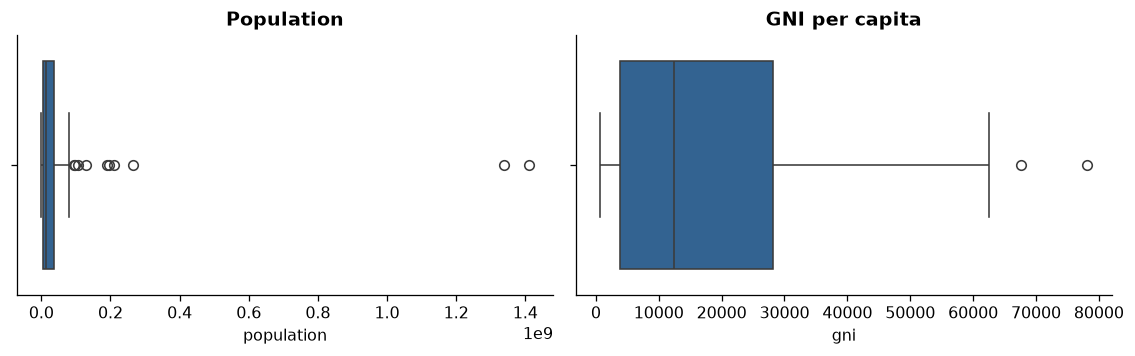

In [13]:
# The 1.5×IQR method flags observations for inspection; it does not justify deleting them.
q1, q3 = X_train[num_columns].quantile(.25), X_train[num_columns].quantile(.75)
iqr = q3 - q1
flags = X_train[num_columns].lt(q1 - 1.5 * iqr) | X_train[num_columns].gt(q3 + 1.5 * iqr)
outlier_count = flags.sum().sort_values(ascending=False).rename('IQR flags')
display(outlier_count.to_frame())
print('Most-flagged countries (by number of variables):')
flagged = X_train[['country']].copy()
flagged['flag_count'] = flags.sum(axis=1)
display(flagged.sort_values('flag_count', ascending=False).head(10))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
sns.boxplot(x=X_train['population'], ax=axes[0]); axes[0].set_title('Population')
sns.boxplot(x=X_train['gni'], ax=axes[1]); axes[1].set_title('GNI per capita')
plt.tight_layout(); plt.show()

### Observations and General Comments

Summarize your key findings from the exploratory analysis. Include:

- Important patterns or relationships identified
- Presence of missing values or outliers
- Potential feature engineering considerations
- Any preprocessing steps that should be applied before modeling

Keep your comments concise and evidence-based.

**Training-set findings.** The five happiness classes are balanced by design, but the regional distribution is uneven. Higher happiness categories generally have higher `gdp_per_capita`, `social_support`, HDI, and life expectancy (see class means and Spearman correlations above). `population` and `gni` have long right tails and IQR outliers; these values are plausible differences between countries, so we retain observations and add log-transformed versions rather than removing countries. Poverty and some development indicators are missing, so the numeric preprocessing uses **training-only median imputation**; `region` uses most-frequent imputation and one-hot encoding. Correlations among HDI, education, and health are strong, so coefficient and SHAP interpretations must account for correlated predictors. The six World Happiness Report factor columns are already *contributions to happiness-score points*, not raw economic or health levels, and may be especially predictive of the corresponding target.

---

## 2. Feature Engineering

### Log Transformations

Apply log transformations to normalize skewed numerical features and improve model stability (if applicable).

> **Note:** Apply every feature engineering step to **both** `X_train` and `X_test`, before fitting the preprocessor in Section 3.

In [14]:
# Generate the same transformations on both partitions without fitting on test data.
for frame in (X_train, X_test):
    frame['log_population'] = np.log1p(frame['population'].clip(lower=0))
    frame['log_gni'] = np.log1p(frame['gni'].clip(lower=0))
print('Created log_population and log_gni (log1p handles zero; missing values stay missing).')

Created log_population and log_gni (log1p handles zero; missing values stay missing).


### Interaction Features

Create at least one interaction feature to capture relationships between existing variables and enhance predictive power.

In [15]:
for frame in (X_train, X_test):
    frame['gdp_x_social_support'] = frame['gdp_per_capita'] * frame['social_support']
    frame['hdi_x_schooling'] = frame['hdi'] * frame['mean_years_of_schooling']
print('Created GDP × social support and HDI × adult schooling interaction features.')

Created GDP × social support and HDI × adult schooling interaction features.


In [16]:
explain("""**Feature choices.** Logs reduce the scale of population and income extremes;
missing values remain missing for later imputation. We retain the original variables
as well as their logs so nonlinear learners can choose useful representations, but
this introduces redundancy and can split SHAP attribution. GDP × social support
allows their joint level to matter; HDI × schooling represents overlapping development
information. These are candidate predictors, not demonstrated causal interactions.
Both train and test receive exactly the same deterministic transformations.""")

**Feature choices.** Logs reduce the scale of population and income extremes;
missing values remain missing for later imputation. We retain the original variables
as well as their logs so nonlinear learners can choose useful representations, but
this introduces redundancy and can split SHAP attribution. GDP × social support
allows their joint level to matter; HDI × schooling represents overlapping development
information. These are candidate predictors, not demonstrated causal interactions.
Both train and test receive exactly the same deterministic transformations.

---

## 3. Data Preprocessing

Use `sklearn`'s `ColumnTransformer` to preprocess the data. Write a preprocessing function and save the fitted preprocessor for later use.

In [17]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Country is excluded (identifier); region is the only categorical predictor.
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = ['region']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler()),
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features),
], remainder='drop', sparse_threshold=0)

# Fit ONLY on training data. A separate alias preserves the naming convention in the prompt.
preprocess = preprocessor.fit(X_train)
print('Preprocessing fitted on', len(X_train), 'training countries only.')
print('Transformed features:', len(preprocess.get_feature_names_out()))

Preprocessing fitted on 95 training countries only.
Transformed features: 37


### Explanation

Briefly explain what the preprocessing steps above do and why they are needed.

If you changed the imputation strategy (or any other preprocessing choice), please state:

- What you changed
- Why you made that change

**Numeric pipeline:** Median imputation handles missing socioeconomic measures without treating missing as observed zero; `add_indicator=True` records missingness, and `StandardScaler` standardizes features using the *fitting fold's* means and standard deviations. **Categorical pipeline:** Most-frequent imputation and `OneHotEncoder(handle_unknown='ignore')` convert region into model-ready columns while tolerating unseen regions. `country` is excluded as an identifier. `ColumnTransformer` combines these matrices.

For ordinary train/test prediction, `preprocess.fit(X_train)` is safe because `X_test` never contributes fitted statistics. **For cross-validation, that same pre-fitted matrix would leak fold-validation information.** Section 6 instead wraps an *unfitted clone* of this transformer and the Random Forest into one `Pipeline` inside `GridSearchCV`, so each fold independently fits its imputation, scaling, missingness indicators, and one-hot categories on its own fitting split. The separate neural-network validation fold is also preprocessed using only the neural-network training subset.

In [18]:
# This is the reusable transformation function; do not fit inside it.
def preprocessor(data):
    return preprocess.transform(data)

X_train_processed = preprocessor(X_train)
X_test_processed = preprocessor(X_test)
assert X_train_processed.shape[1] == X_test_processed.shape[1]
assert np.isfinite(X_train_processed).all() and np.isfinite(X_test_processed).all()
print('Train matrix:', X_train_processed.shape, 'Test matrix:', X_test_processed.shape)

Train matrix: (95, 37) Test matrix: (42, 37)


### Conceptual Question

Explain the differences between the following:

- The `preprocessor` **object**
- The `preprocess` **object**
- The `preprocessor` **function**
- The final `preprocessed_data` **returned**

Clearly distinguish between objects, functions, and transformed data.

- **`preprocessor` object (before the later function definition):** The `ColumnTransformer` built from separate numerical and categorical processing branches. It is created before fitting. The assignment's original variable name is subsequently reused as a function name, shadowing that object.
- **`preprocess` object:** The fitted `ColumnTransformer`, which stores training-derived imputations, scales, and categories.
- **`preprocessor(data)` function:** Calls `preprocess.transform(data)` without fitting; it returns transformed numeric features in the same order.
- **`preprocessed_data`:** The resulting numeric array of country rows by transformed features, not a learned transformer. In Section 6, `clone(preprocess)` creates a *new unfitted copy* inside each cross-validation pipeline.

In [19]:
# check shape of X data after preprocessing it using our new function
preprocessor(X_train).shape

(95, 37)

---

## 4. Model Training and Saving Artifacts

Fit the model on the preprocessed training data. Save the fitted preprocessor and the trained model for reuse (e.g., to make predictions later without retraining).

In [20]:
import joblib
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Shared evaluation table built from HELD-OUT TEST observations only.
model_results = []
prediction_registry = {}
def evaluate_classifier(name, truth, preds, show_report=True):
    truth = np.asarray(truth, dtype=int)
    preds = np.asarray(preds, dtype=int)
    scores = {'Model': name, 'Test accuracy': accuracy_score(truth, preds),
              'Test macro F1': f1_score(truth, preds, average='macro', zero_division=0)}
    model_results.append(scores)
    prediction_registry[name] = preds.copy()
    print(f"{name}: test accuracy={scores['Test accuracy']:.3f}, "
          f"macro F1={scores['Test macro F1']:.3f}")
    if show_report:
        print(classification_report(truth, preds, labels=np.arange(5), target_names=CLASS_NAMES, zero_division=0))
        display(pd.DataFrame(confusion_matrix(truth, preds, labels=np.arange(5)),
                             index=CLASS_NAMES, columns=CLASS_NAMES))
    return scores

rf_baseline = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf_baseline.fit(X_train_processed, y_train_labels)
model = rf_baseline  # Keep the prompt's variable name for the first model.
print('Random forest baseline training accuracy:', round(model.score(X_train_processed, y_train_labels), 3))
Path('artifacts').mkdir(exist_ok=True)
joblib.dump({'preprocessor': preprocess, 'model': model, 'classes': CLASS_NAMES},
            'artifacts/random_forest_baseline.joblib')
print('Saved artifacts/random_forest_baseline.joblib')

Random forest baseline training accuracy: 1.0
Saved artifacts/random_forest_baseline.joblib


---

## 5. Model Evaluation

Generate predictions using `X_test`. Compare the predictions with the true labels in `y_test` using appropriate evaluation metrics.

In [21]:
prediction_labels = model.predict(preprocessor(X_test))
baseline_scores = evaluate_classifier('RF baseline', y_test_labels, prediction_labels)

RF baseline: test accuracy=0.548, macro F1=0.548
              precision    recall  f1-score   support

    Very Low       0.43      0.33      0.38         9
         Low       0.22      0.25      0.24         8
     Average       0.55      0.75      0.63         8
        High       0.75      0.75      0.75         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.55        42
   macro avg       0.56      0.55      0.55        42
weighted avg       0.56      0.55      0.55        42



,Very Low,Low,Average,High,Very High
Very Low,3,6,0,0,0
Low,4,2,2,0,0
Average,0,1,6,1,0
High,0,0,1,6,1
Very High,0,0,2,1,6


---

## 6. Hyperparameter Experimentation

Repeat the training and evaluation process with different model parameters to improve performance. Track results across experiments and report the best-performing configuration.

In [22]:
# Model 2: more trees, restrict depth, and larger leaves to reduce variance.
model_2 = RandomForestClassifier(n_estimators=300, max_depth=8,
                                  min_samples_leaf=2, max_features='sqrt',
                                  random_state=SEED, n_jobs=-1)
model_2.fit(X_train_processed, y_train_labels)
print('Model 1 train accuracy:', round(model.score(X_train_processed, y_train_labels), 3))
print('Model 2 train accuracy:', round(model_2.score(X_train_processed, y_train_labels), 3))

Model 1 train accuracy: 1.0


Model 2 train accuracy: 0.989


### Reflection on Hyperparameter Changes

Briefly explain:

- What parameters you changed
- What each parameter controls
- Why the changes improved (or did not improve) performance

Support your explanation with evidence from your results.

In [23]:
model_2_preview = model_2.predict(X_test_processed)
preview_accuracy = accuracy_score(y_test_labels, model_2_preview)
preview_f1 = f1_score(y_test_labels, model_2_preview, average='macro')
explain(f"""Model 2 changes **200 → 300 trees**, **unbounded depth → max_depth=8**,
and **min_samples_leaf=1 → 2**. More trees stabilize the ensemble; shallower trees
and larger leaves discourage overly specific splits. `max_features='sqrt'` is
**unchanged** from the baseline default and randomly restricts predictors at each split.
Training accuracy changes from {rf_baseline.score(X_train_processed,y_train_labels):.3f}
to {model_2.score(X_train_processed,y_train_labels):.3f}; test accuracy changes from
{baseline_scores['Test accuracy']:.3f} to {preview_accuracy:.3f}, and macro F1 from
{baseline_scores['Test macro F1']:.3f} to {preview_f1:.3f}. The accuracy difference is
{(preview_accuracy-baseline_scores['Test accuracy'])*len(y_test):+.0f} correctly classified
countries out of 42. This is a small, split-dependent change, not strong evidence
that the new hyperparameters generalize better.""")

Model 2 changes **200 → 300 trees**, **unbounded depth → max_depth=8**,
and **min_samples_leaf=1 → 2**. More trees stabilize the ensemble; shallower trees
and larger leaves discourage overly specific splits. `max_features='sqrt'` is
**unchanged** from the baseline default and randomly restricts predictors at each split.
Training accuracy changes from 1.000
to 0.989; test accuracy changes from
0.548 to 0.571, and macro F1 from
0.548 to 0.574. The accuracy difference is
+1 correctly classified
countries out of 42. This is a small, split-dependent change, not strong evidence
that the new hyperparameters generalize better.

In [24]:
prediction_labels = model_2.predict(preprocessor(X_test))
rf_tuned_scores = evaluate_classifier('RF manually tuned', y_test_labels, prediction_labels)
print(f"Change from baseline: accuracy {rf_tuned_scores['Test accuracy']-baseline_scores['Test accuracy']:+.3f}, "
      f"macro F1 {rf_tuned_scores['Test macro F1']-baseline_scores['Test macro F1']:+.3f}")

RF manually tuned: test accuracy=0.571, macro F1=0.574
              precision    recall  f1-score   support

    Very Low       0.67      0.44      0.53         9
         Low       0.40      0.50      0.44         8
     Average       0.46      0.75      0.57         8
        High       0.67      0.50      0.57         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.57        42
   macro avg       0.61      0.57      0.57        42
weighted avg       0.62      0.57      0.58        42



,Very Low,Low,Average,High,Very High
Very Low,4,5,0,0,0
Low,2,4,2,0,0
Average,0,1,6,1,0
High,0,0,3,4,1
Very High,0,0,2,1,6


Change from baseline: accuracy +0.024, macro F1 +0.026


### Discussion Question

Do you think it is worth making more changes to the parameters? Should we keep trying random values and see what works better? What is an alternative to doing this manually?

Testing arbitrary parameter combinations by repeatedly examining test-set scores is unreliable: it indirectly tunes to the held-out countries. A better workflow is to specify a search space in advance, use **stratified cross-validation entirely within the 95-country training set**, and choose the hyperparameters by mean validation macro F1. `GridSearchCV` or `RandomizedSearchCV` automates this search. Crucially, imputation, standardization, and region encoding must be refitted **inside every cross-validation training fold**, not once on all 95 countries. The next cell therefore searches over a complete `Pipeline(preprocessor, RandomForestClassifier)`. Its best pipeline is refitted on all training countries; the untouched 42-country test set is used only for final descriptive evaluation.

### Grid Search (Model 3)

Use `GridSearchCV` to search systematically over Random Forest hyperparameters.

In [25]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define all choices before consulting the held-out test set.
# Step prefixes are required because GridSearchCV tunes a complete Pipeline.
param_grid = {
    'classifier__n_estimators': np.arange(100, 301, 200),
    'classifier__max_depth': [None, 8],
    'classifier__min_samples_leaf': np.arange(1, 3),
}
rf_for_search = Pipeline(steps=[
    ('preprocess', clone(preprocess)),  # clone resets previously fitted state!
    ('classifier', RandomForestClassifier(random_state=SEED, n_jobs=1,
                                           max_features='sqrt')),
])
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
gridmodel = GridSearchCV(
    estimator=rf_for_search,
    param_grid=param_grid, cv=cv, scoring='f1_macro',
    n_jobs=1, refit=True, return_train_score=True,
)
# RAW, non-fitted data: each fold learns its own imputation/scaling/encoding.
gridmodel.fit(X_train, y_train_labels)
assert isinstance(gridmodel.best_estimator_.named_steps['preprocess'], ColumnTransformer)
print('Leakage-safe mean CV macro F1: {:.3f}'.format(gridmodel.best_score_))
print('Best pipeline parameters:', gridmodel.best_params_)
grid_predictions = gridmodel.predict(X_test)
joblib.dump({'pipeline': gridmodel.best_estimator_, 'classes': CLASS_NAMES},
            'artifacts/random_forest_grid_best.joblib')
print('Saved artifacts/random_forest_grid_best.joblib (preprocessing + classifier; expects engineered columns)')
display(pd.DataFrame(gridmodel.cv_results_)[
    ['params', 'mean_test_score', 'std_test_score', 'mean_train_score']
].sort_values('mean_test_score', ascending=False).head(8))

Leakage-safe mean CV macro F1: 0.608
Best pipeline parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': np.int64(1), 'classifier__n_estimators': np.int64(100)}
Saved artifacts/random_forest_grid_best.joblib (preprocessing + classifier; expects engineered columns)


,params,mean_test_score,std_test_score,mean_train_score
0,"{'classifier__max_depth': None, 'classifier__m...",0.607529,0.046898,1.0
4,"{'classifier__max_depth': 8, 'classifier__min_...",0.607529,0.046898,1.0
1,"{'classifier__max_depth': None, 'classifier__m...",0.532019,0.037563,1.0
5,"{'classifier__max_depth': 8, 'classifier__min_...",0.532019,0.037563,1.0
3,"{'classifier__max_depth': None, 'classifier__m...",0.530706,0.043732,1.0
7,"{'classifier__max_depth': 8, 'classifier__min_...",0.530706,0.043732,1.0
2,"{'classifier__max_depth': None, 'classifier__m...",0.514595,0.065493,1.0
6,"{'classifier__max_depth': 8, 'classifier__min_...",0.514595,0.065493,1.0


In [26]:
prediction_labels = grid_predictions
grid_scores = evaluate_classifier('RF grid search', y_test_labels, prediction_labels)
print('These are held-out test scores, not the same as the cross-validation score above.')

RF grid search: test accuracy=0.500, macro F1=0.501
              precision    recall  f1-score   support

    Very Low       0.43      0.33      0.38         9
         Low       0.22      0.25      0.24         8
     Average       0.46      0.75      0.57         8
        High       0.67      0.50      0.57         8
   Very High       0.86      0.67      0.75         9

    accuracy                           0.50        42
   macro avg       0.53      0.50      0.50        42
weighted avg       0.53      0.50      0.50        42



,Very Low,Low,Average,High,Very High
Very Low,3,6,0,0,0
Low,4,2,2,0,0
Average,0,1,6,1,0
High,0,0,3,4,1
Very High,0,0,2,1,6


These are held-out test scores, not the same as the cross-validation score above.


### Other Classical Models

Train at least one other model from the list below and compare it with your Random Forest models.

In [27]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

svc_model = SVC(kernel='rbf', C=2.0, gamma='scale', random_state=SEED)
svc_model.fit(X_train_processed, y_train_labels)
svc_scores = evaluate_classifier('SVC (RBF)', y_test_labels,
                                 svc_model.predict(X_test_processed), show_report=False)
knn_model = KNeighborsClassifier(n_neighbors=7, weights='distance')
knn_model.fit(X_train_processed, y_train_labels)
knn_scores = evaluate_classifier('KNN (k=7)', y_test_labels,
                                 knn_model.predict(X_test_processed), show_report=False)
model = svc_model  # The later tree SHAP analysis explicitly selects the grid-search tree.
display(pd.DataFrame(model_results).set_index('Model').round(3))

# An independent, train-only selection benchmark for the PRE-SPECIFIED models.
# Each fold fits its OWN preprocessing, so validation rows affect no fitted statistic.
cv_candidates = {
    'RF baseline': RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
    'RF manually tuned': RandomForestClassifier(n_estimators=300, max_depth=8,
              min_samples_leaf=2, max_features='sqrt', random_state=SEED, n_jobs=1),
    'SVC (RBF)': SVC(kernel='rbf', C=2.0, gamma='scale', random_state=SEED),
    'KNN (k=7)': KNeighborsClassifier(n_neighbors=7, weights='distance'),
}
cv_scores = {}
for candidate_name, estimator in cv_candidates.items():
    pipeline = Pipeline([('preprocess', clone(preprocess)),
                         ('classifier', clone(estimator))])
    fold_scores = cross_val_score(pipeline, X_train, y_train_labels,
                                  scoring='f1_macro', cv=cv, n_jobs=1)
    cv_scores[candidate_name] = {'CV mean macro F1': fold_scores.mean(),
                                  'CV std': fold_scores.std(), 'Folds': len(fold_scores)}
cv_selection_table = pd.DataFrame(cv_scores).T.sort_values('CV mean macro F1', ascending=False)
print('Training-only cross-validation (not selected using test scores):')
display(cv_selection_table.round(3))
selected_classical = cv_selection_table.index[0]
print('CV-selected, prespecified classical model:', selected_classical)
print('Note: GridSearchCV best_score_ estimates the tuned RF, but is optimistic for'
      ' direct model-family selection because the same folds chose its parameters.')

SVC (RBF): test accuracy=0.595, macro F1=0.596
KNN (k=7): test accuracy=0.571, macro F1=0.576


,Test accuracy,Test macro F1
Model,,
RF baseline,0.548,0.548
RF manually tuned,0.571,0.574
RF grid search,0.500,0.501
SVC (RBF),0.595,0.596
KNN (k=7),0.571,0.576


Training-only cross-validation (not selected using test scores):


,CV mean macro F1,CV std,Folds
RF baseline,0.560,0.050,4.0
KNN (k=7),0.541,0.032,4.0
RF manually tuned,0.531,0.044,4.0
SVC (RBF),0.485,0.055,4.0


CV-selected, prespecified classical model: RF baseline
Note: GridSearchCV best_score_ estimates the tuned RF, but is optimistic for direct model-family selection because the same folds chose its parameters.


### Discussion Question

Describe the parameters you defined in `GradientBoostingClassifier`, and/or `BaggingClassifier`, and/or `KNN`, and/or `SVC`. What worked and why?

In [28]:
explain(f"""The **RBF SVC** uses `C=2.0`, which controls the penalty for classification
errors relative to regularization, and `gamma='scale'`, which sets kernel width from
feature count and variance. **KNN** uses seven neighbors and distance weighting, so
nearby countries contribute more strongly; standardized numeric features make the
distance comparison more meaningful.

On this test split, SVC accuracy/macro F1 are **{svc_scores['Test accuracy']:.3f} /
{svc_scores['Test macro F1']:.3f}** and KNN's are **{knn_scores['Test accuracy']:.3f} /
{knn_scores['Test macro F1']:.3f}**. Their training-only four-fold CV macro F1 values
are **{cv_scores['SVC (RBF)']['CV mean macro F1']:.3f}** and
**{cv_scores['KNN (k=7)']['CV mean macro F1']:.3f}**, respectively. The prespecified
classical CV choice is **{selected_classical}**. A nonlinear kernel and local neighborhoods
can capture country similarities, but the differing test/CV rankings show that this
sample does not identify one uniformly superior method. We did not tune SVC or KNN
against the test set. GridSearchCV's best score is reported separately because the
same folds selected its RF parameters; nested CV would be needed for an unbiased
evaluation of that complete search procedure.""")

The **RBF SVC** uses `C=2.0`, which controls the penalty for classification
errors relative to regularization, and `gamma='scale'`, which sets kernel width from
feature count and variance. **KNN** uses seven neighbors and distance weighting, so
nearby countries contribute more strongly; standardized numeric features make the
distance comparison more meaningful.

On this test split, SVC accuracy/macro F1 are **0.595 /
0.596** and KNN's are **0.571 /
0.576**. Their training-only four-fold CV macro F1 values
are **0.485** and
**0.541**, respectively. The prespecified
classical CV choice is **RF baseline**. A nonlinear kernel and local neighborhoods
can capture country similarities, but the differing test/CV rankings show that this
sample does not identify one uniformly superior method. We did not tune SVC or KNN
against the test set. GridSearchCV's best score is reported separately because the
same folds selected its RF parameters; nested CV would be needed for an unbiased
evaluation of that complete search procedure.

---

## 7. Basic Deep Learning

In [29]:
# Keras workflow: Keras Sequential -> Dense -> compile -> fit -> validation.
# Stratify the INNER neural holdout; learn preprocessing on inner-fit rows only.
import keras
from keras import layers
keras.utils.set_random_seed(SEED)
n_classes = len(CLASS_NAMES)
inner_fit_idx, inner_val_idx = train_test_split(
    np.arange(len(X_train)), test_size=.25,
    random_state=SEED, stratify=y_train_labels.to_numpy())
nn_order = np.r_[inner_fit_idx, inner_val_idx]
nn_split_at = len(inner_fit_idx)
nn_labels = y_train_labels.to_numpy()[nn_order]
nn_preprocess = clone(preprocess).fit(X_train.iloc[inner_fit_idx])
train_nn = nn_preprocess.transform(X_train.iloc[nn_order]).astype('float32')
test_nn = nn_preprocess.transform(X_test).astype('float32')
feature_count = train_nn.shape[1]
y_train_oh = pd.DataFrame(np.eye(n_classes, dtype='float32')[nn_labels], columns=CLASS_NAMES)
assert y_train_oh.shape == (len(X_train), 5)
assert nn_split_at == len(train_nn) - len(inner_val_idx)
print('Stratified neural fit/validation:', nn_split_at, '/', len(inner_val_idx))
print('Fit class counts:', np.bincount(nn_labels[:nn_split_at], minlength=n_classes))
print('Validation class counts:', np.bincount(nn_labels[nn_split_at:], minlength=n_classes))

keras_model = keras.Sequential([
    layers.Input(shape=(feature_count,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
])
keras_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
history = keras_model.fit(train_nn, y_train_oh.to_numpy(), batch_size=20,
                          epochs=300, validation_split=.25, verbose=0)
print('SGD 300 epochs | final train loss {:.3f}, validation loss {:.3f}'.format(
      history.history['loss'][-1], history.history['val_loss'][-1]))


Stratified neural fit/validation: 71 / 24
Fit class counts: [14 15 14 14 14]
Validation class counts: [5 4 5 5 5]


SGD 300 epochs | final train loss 0.147, validation loss 1.290


### Discussion Question

Which activation functions did you use in the hidden layers? Why was **softmax** used in the final layer?

The four hidden layers use **ReLU**, `max(0, x)`, which is computationally simple and usually trains faster than saturating nonlinearities. The final layer uses **softmax** because each country must be assigned to one of five mutually exclusive happiness groups: it converts five logits into nonnegative class probabilities summing to one.

### Discussion Question

Was it a good idea to train for 300 epochs? Should you train longer? Why or why not?

In [30]:
best_base_epoch = int(np.argmin(history.history['val_loss'])) + 1
base_epoch_assessment = ('The final epoch is past the validation-loss optimum, with evidence of overfitting.'
                         if best_base_epoch < len(history.history['val_loss']) and
                         history.history['val_loss'][-1] > min(history.history['val_loss']) + 0.05
                         else 'This run does not show a clear late validation-loss increase; an epoch cap alone cannot establish the ideal training length.')
explain(f"""**{base_epoch_assessment}** Validation loss reaches its minimum
of **{min(history.history['val_loss']):.3f} at epoch {best_base_epoch}**, but finishes at
**{history.history['val_loss'][-1]:.3f}** while training loss falls to
**{history.history['loss'][-1]:.3f}**. Continuing to minimize training loss is not a
reason to train longer. An early-stopping rule should restore the validation-selected
weights; the required baseline is deliberately evaluated after all 300 epochs to
show this problem. Only {nn_split_at} countries train the network weights and
{len(inner_val_idx)} validate them, so this large network has substantial variance.
A smaller network and repeated internal splits would be useful next checks.""")

**The final epoch is past the validation-loss optimum, with evidence of overfitting.** Validation loss reaches its minimum
of **0.925 at epoch 121**, but finishes at
**1.290** while training loss falls to
**0.147**. Continuing to minimize training loss is not a
reason to train longer. An early-stopping rule should restore the validation-selected
weights; the required baseline is deliberately evaluated after all 300 epochs to
show this problem. Only 71 countries train the network weights and
24 validate them, so this large network has substantial variance.
A smaller network and repeated internal splits would be useful next checks.

### Discussion Question

Why was `loss='categorical_crossentropy'` and `optimizer='sgd'` used? Would you change anything? Why or why not?

`categorical_crossentropy` is appropriate because the labels are **one-hot encoded across five mutually exclusive classes**; it penalizes low predicted probabilities for the true class. Plain SGD is a simple, interpretable baseline optimizer but can converge slowly without a tuned learning rate or momentum. Adam often converges faster, so I use it with early stopping for the regularized follow-up, while keeping the specified SGD baseline for comparison. For integer labels, `sparse_categorical_crossentropy` would remove the need for one-hot encoding.

### Plot Training Curves

Extract the model training history and plot the learning curves (e.g., training vs. validation loss and accuracy) across epochs.

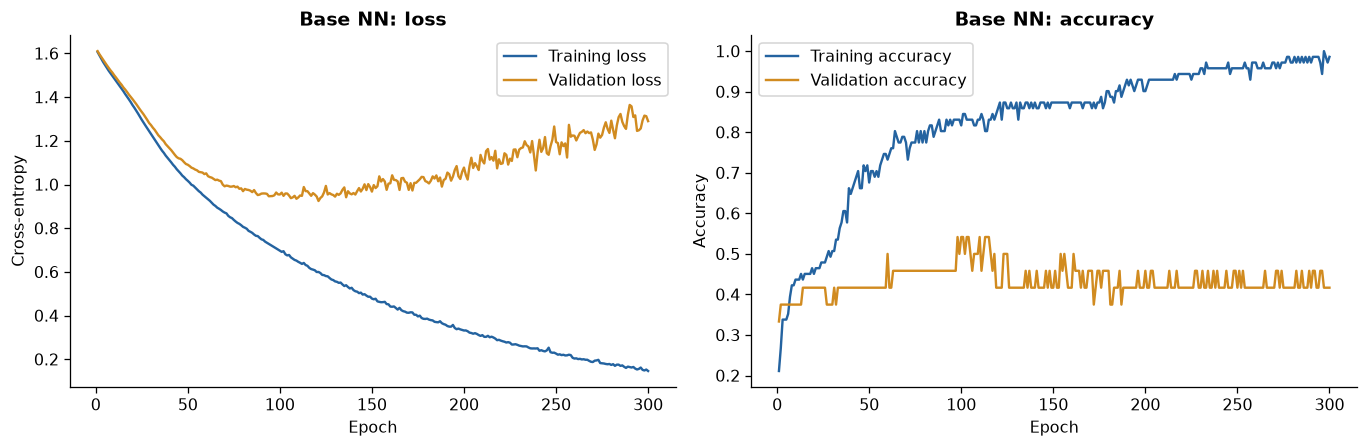

Lowest validation loss: 0.925 at epoch 121


In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.arange(1, len(history.history['loss'])+1), history.history['loss'], label='Training loss')
ax[0].plot(np.arange(1, len(history.history['val_loss'])+1), history.history['val_loss'], label='Validation loss')
ax[0].set(xlabel='Epoch', ylabel='Cross-entropy', title='Base NN: loss')
ax[1].plot(np.arange(1, len(history.history['accuracy'])+1), history.history['accuracy'], label='Training accuracy')
ax[1].plot(np.arange(1, len(history.history['val_accuracy'])+1), history.history['val_accuracy'], label='Validation accuracy')
ax[1].set(xlabel='Epoch', ylabel='Accuracy', title='Base NN: accuracy')
for axis in ax: axis.legend()
plt.tight_layout(); plt.show()
print('Lowest validation loss:', round(min(history.history['val_loss']), 3),
      'at epoch', np.argmin(history.history['val_loss']) + 1)

### Evaluate the Neural Network on the Test Set

In [32]:
# Argmax gives the index of the most probable happiness category.
base_probs = keras_model.predict(test_nn, verbose=0)
prediction_column_index = np.argmax(base_probs, axis=1)
prediction_labels = [y_train_oh.columns[i] for i in prediction_column_index]
base_nn_scores = evaluate_classifier('NN base (SGD, 300 epochs)', y_test_labels,
                                     prediction_column_index)
base_nn_test_loss, base_nn_test_accuracy = keras_model.evaluate(
    test_nn, np.eye(n_classes)[y_test_labels.to_numpy()], verbose=0)
print('Base NN test cross-entropy:', round(float(base_nn_test_loss), 3))

NN base (SGD, 300 epochs): test accuracy=0.500, macro F1=0.490
              precision    recall  f1-score   support

    Very Low       0.40      0.44      0.42         9
         Low       0.14      0.12      0.13         8
     Average       0.62      0.62      0.62         8
        High       0.67      0.50      0.57         8
   Very High       0.64      0.78      0.70         9

    accuracy                           0.50        42
   macro avg       0.49      0.49      0.49        42
weighted avg       0.50      0.50      0.49        42



,Very Low,Low,Average,High,Very High
Very Low,4,5,0,0,0
Low,5,1,1,0,1
Average,1,1,5,0,1
High,0,0,2,4,2
Very High,0,0,0,2,7


Base NN test cross-entropy: 1.346


### Regularization: Dropout and Batch Normalization

Implement regularization techniques such as **Dropout** and **Batch Normalization** to improve generalization and observe the change in performance.

> **Note:** Compare training vs. test (or validation) loss and accuracy before and after adding regularization.

NN dropout + batch norm: test accuracy=0.571, macro F1=0.563
Epochs run: 63
Base NN test loss/accuracy: 1.346 0.5
Regularized NN test loss/accuracy: 1.002 0.571


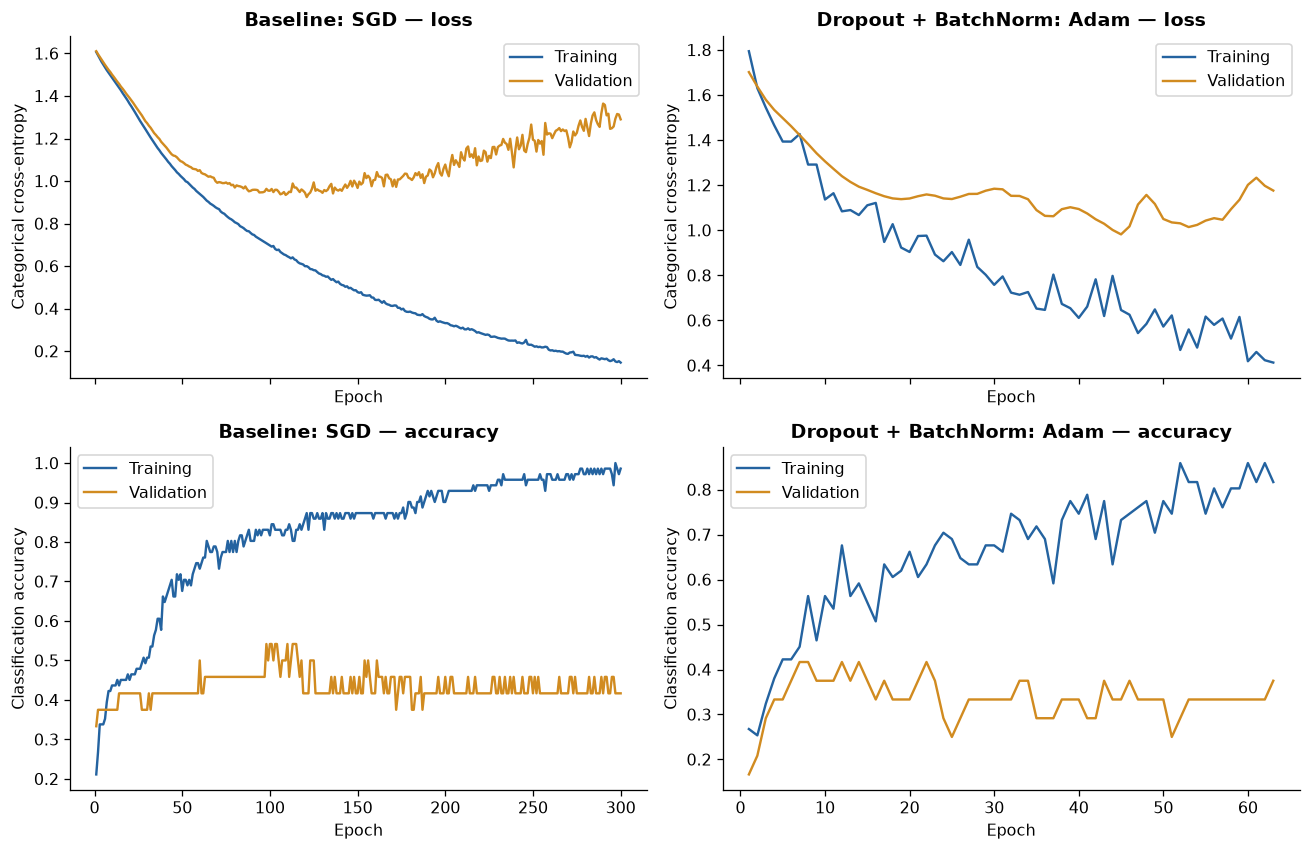

Use the controlled four-model ablation below to isolate regularization effects.


In [33]:
# Dropout + batch normalization + early stopping; same five Dense widths, Adam optimizer.
keras.utils.set_random_seed(SEED)
regularized_model = keras.Sequential([
    layers.Input(shape=(feature_count,)),
    layers.Dense(128), layers.BatchNormalization(), layers.Activation('relu'),
    layers.Dropout(.25),
    layers.Dense(64), layers.BatchNormalization(), layers.Activation('relu'),
    layers.Dropout(.25),
    layers.Dense(64, activation='relu'), layers.Dropout(.15),
    layers.Dense(32, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
])
regularized_model.compile(loss='categorical_crossentropy', optimizer=keras.optimizers.Adam(learning_rate=.001),
                          metrics=['accuracy'])
early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=18,
                                              restore_best_weights=True)
regularized_history = regularized_model.fit(
    train_nn, y_train_oh.to_numpy(), epochs=180, batch_size=20, validation_split=.25,
    callbacks=[early_stopping], verbose=0)
reg_loss, reg_accuracy = regularized_model.evaluate(
    test_nn, np.eye(n_classes)[y_test_labels.to_numpy()], verbose=0)
reg_preds = np.argmax(regularized_model.predict(test_nn, verbose=0), axis=1)
reg_scores = evaluate_classifier('NN dropout + batch norm', y_test_labels, reg_preds,
                                  show_report=False)
print('Epochs run:', len(regularized_history.history['loss']))
print('Base NN test loss/accuracy:', round(float(base_nn_test_loss),3),
      round(float(base_nn_test_accuracy),3))
print('Regularized NN test loss/accuracy:', round(float(reg_loss),3),
      round(float(reg_accuracy),3))
# Compare training AND validation loss/accuracy for each architecture.
# Note: these two examples have different optimizers and training policies,
# so the charts are descriptive rather than proof of Dropout/BN effects.
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.5), sharex='col')
for col, (title, run_history) in enumerate([
    ('Baseline: SGD', history.history),
    ('Dropout + BatchNorm: Adam', regularized_history.history),
]):
    for row, (metric, ylab) in enumerate([
        ('loss', 'Categorical cross-entropy'),
        ('accuracy', 'Classification accuracy'),
    ]):
        axes[row, col].plot(np.arange(1,len(run_history[metric])+1), run_history[metric], label='Training')
        axes[row, col].plot(np.arange(1,len(run_history[f'val_{metric}'])+1), run_history[f'val_{metric}'], label='Validation')
        axes[row, col].set_title(f'{title} — {metric}')
        axes[row, col].set_ylabel(ylab)
        axes[row, col].set_xlabel('Epoch')
        axes[row, col].legend()
plt.tight_layout(); plt.show()
print('Use the controlled four-model ablation below to isolate regularization effects.')

In [34]:
explain(f"""The original regularized example combines Dropout and BatchNorm with
Adam and early stopping, while the baseline uses SGD for 300 epochs. Test loss changes
from **{float(base_nn_test_loss):.3f}** to **{float(reg_loss):.3f}**, and accuracy from
**{float(base_nn_test_accuracy):.3f}** to **{float(reg_accuracy):.3f}**. These are descriptive
results: changing the optimizer and stopping policy at the same time prevents us from
attributing the difference to regularization alone.

The next four-way experiment holds the split, widths, Adam learning rate, batch size,
epoch cap and stopping rule fixed. It compares no regularization, Dropout, BatchNorm,
and both, selecting by validation loss. Training curves with Dropout include stochastic
masking and BatchNorm uses training statistics, whereas validation runs in inference
mode; differences between those curves are not entirely an overfitting measure.""")

The original regularized example combines Dropout and BatchNorm with
Adam and early stopping, while the baseline uses SGD for 300 epochs. Test loss changes
from **1.346** to **1.002**, and accuracy from
**0.500** to **0.571**. These are descriptive
results: changing the optimizer and stopping policy at the same time prevents us from
attributing the difference to regularization alone.

The next four-way experiment holds the split, widths, Adam learning rate, batch size,
epoch cap and stopping rule fixed. It compares no regularization, Dropout, BatchNorm,
and both, selecting by validation loss. Training curves with Dropout include stochastic
masking and BatchNorm uses training statistics, whereas validation runs in inference
mode; differences between those curves are not entirely an overfitting measure.

### Controlled regularization comparison

All four variants use 128 → 64 → 64 → 32 → 5 units, Adam with learning rate 0.001,
batch size 20, a maximum of 100 epochs and early-stopping patience 15. The same
71/24 split and initial seed are used. Dropout is 0.20 after the first three hidden
layers; BatchNorm, when enabled, is used before each hidden activation.

The validation loss selects the variant. Remaining test evaluations are deferred to
the final reporting step, after all model decisions have been fixed.

,Best validation loss,Validation accuracy at chosen epoch,Best epoch,Epochs run
Variant,,,,
Dropout + BatchNorm (Adam),0.968,0.542,51,66
No regularization (Adam),1.014,0.583,11,26
Dropout only (Adam),1.021,0.417,24,39
BatchNorm only (Adam),1.252,0.375,23,38


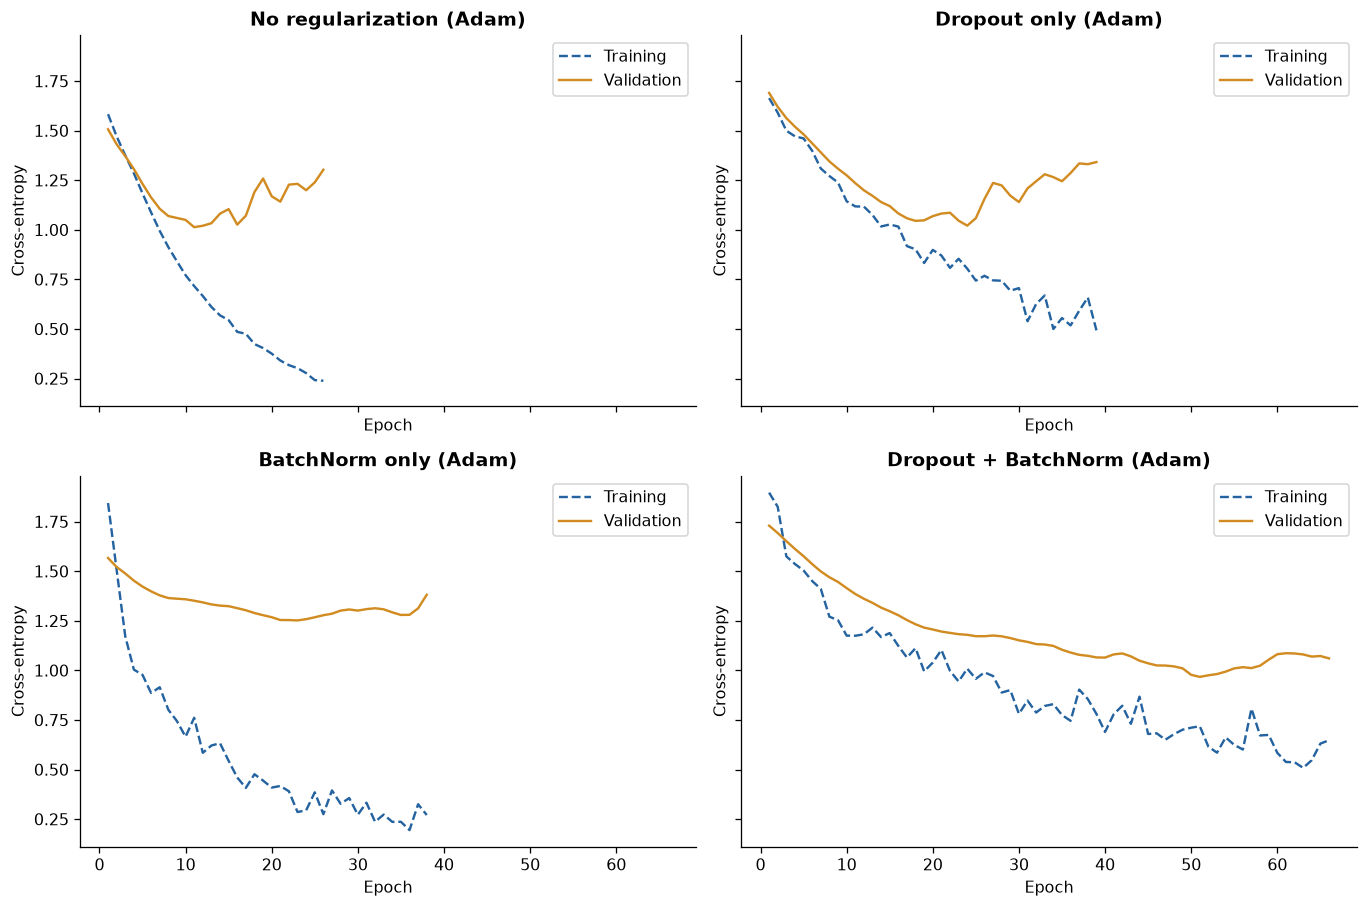

NN validation-selected (Dropout + BatchNorm (Adam)): test accuracy=0.571, macro F1=0.564
Validation-selected variant: Dropout + BatchNorm (Adam)
Only the validation-selected variant received a NEW held-out test score.


**Observed comparison.** Validation loss selects **Dropout + BatchNorm (Adam)**
(best loss 0.968, epoch
51). The full table shows whether each added
component improves the same validation criterion relative to no regularization.
Relative to no regularization (loss 1.014),
Dropout alone gives 1.021,
BatchNorm alone 1.252,
and their combination 0.968.
This is a single-seed, 24-country comparison; it does not establish that Dropout or
BatchNorm is universally helpful or harmful. The test scores of all four fixed
configurations will appear in the final comparison.

In [35]:
# Four variants with the same optimizer, data and training policy.
# ONLY model selected by neural validation cross-entropy is evaluated on held-out test.
regularization_configs = {
    'No regularization (Adam)': (False, False),
    'Dropout only (Adam)': (True, False),
    'BatchNorm only (Adam)': (False, True),
    'Dropout + BatchNorm (Adam)': (True, True),
}

def make_regularization_network(use_dropout, use_bn):
    parts = [layers.Input(shape=(feature_count,))]
    for idx, width in enumerate((128, 64, 64, 32)):
        parts.append(layers.Dense(width))
        if use_bn:
            parts.append(layers.BatchNormalization())
        parts.append(layers.Activation('relu'))
        if use_dropout and idx < 3:
            parts.append(layers.Dropout(.20))
    parts.append(layers.Dense(n_classes, activation='softmax'))
    model = keras.Sequential(parts)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=.001),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model

control_rows, control_histories, control_models = [], {}, {}
for variant_name, (dropout_flag, bn_flag) in regularization_configs.items():
    keras.utils.set_random_seed(SEED)
    fitted_net = make_regularization_network(dropout_flag, bn_flag)
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15,
                                        restore_best_weights=True)
    h = fitted_net.fit(train_nn, y_train_oh.to_numpy(), epochs=100,
                       batch_size=20, validation_split=.25,
                       callbacks=[stop], verbose=0).history
    chosen_i = int(np.argmin(h['val_loss']))
    control_rows.append({'Variant': variant_name,
         'Best validation loss': float(h['val_loss'][chosen_i]),
         'Validation accuracy at chosen epoch': float(h['val_accuracy'][chosen_i]),
         'Best epoch': chosen_i + 1, 'Epochs run': len(h['loss'])})
    control_histories[variant_name] = h
    control_models[variant_name] = fitted_net
controlled_df = (pd.DataFrame(control_rows).set_index('Variant')
                 .sort_values('Best validation loss'))
display(controlled_df.round(3))
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, (name, h) in zip(axes.flat, control_histories.items()):
    epochs_axis = np.arange(1, len(h['loss'])+1)
    ax.plot(epochs_axis, h['loss'], label='Training', linestyle='--')
    ax.plot(epochs_axis, h['val_loss'], label='Validation')
    ax.set(title=name, xlabel='Epoch', ylabel='Cross-entropy')
    ax.legend()
plt.tight_layout(); plt.show()
chosen_variant = controlled_df.index[0]
chosen_probs = control_models[chosen_variant].predict(test_nn, verbose=0)
controlled_scores = evaluate_classifier(f'NN validation-selected ({chosen_variant})',
    y_test_labels, chosen_probs.argmax(axis=1), show_report=False)
print('Validation-selected variant:', chosen_variant)
print('Only the validation-selected variant received a NEW held-out test score.')

explain(f"""**Observed comparison.** Validation loss selects **{chosen_variant}**
(best loss {controlled_df.iloc[0]['Best validation loss']:.3f}, epoch
{int(controlled_df.iloc[0]['Best epoch'])}). The full table shows whether each added
component improves the same validation criterion relative to no regularization.
Relative to no regularization (loss {controlled_df.loc['No regularization (Adam)', 'Best validation loss']:.3f}),
Dropout alone gives {controlled_df.loc['Dropout only (Adam)', 'Best validation loss']:.3f},
BatchNorm alone {controlled_df.loc['BatchNorm only (Adam)', 'Best validation loss']:.3f},
and their combination {controlled_df.loc['Dropout + BatchNorm (Adam)', 'Best validation loss']:.3f}.
This is a single-seed, 24-country comparison; it does not establish that Dropout or
BatchNorm is universally helpful or harmful. The test scores of all four fixed
configurations will appear in the final comparison.""")

### Activation Function Experimentation

Experiment with different activation functions — **ReLU**, **LeakyReLU**, **Tanh**, and **Sigmoid** — and compare their impact on model performance.

,Best validation loss,Best epoch,Validation accuracy AT chosen epoch,Epochs run
Activation,,,,
ReLU,1.014,11,0.583,26
LeakyReLU,1.063,11,0.542,26
Tanh,0.970,7,0.333,22
Sigmoid,0.993,70,0.500,70


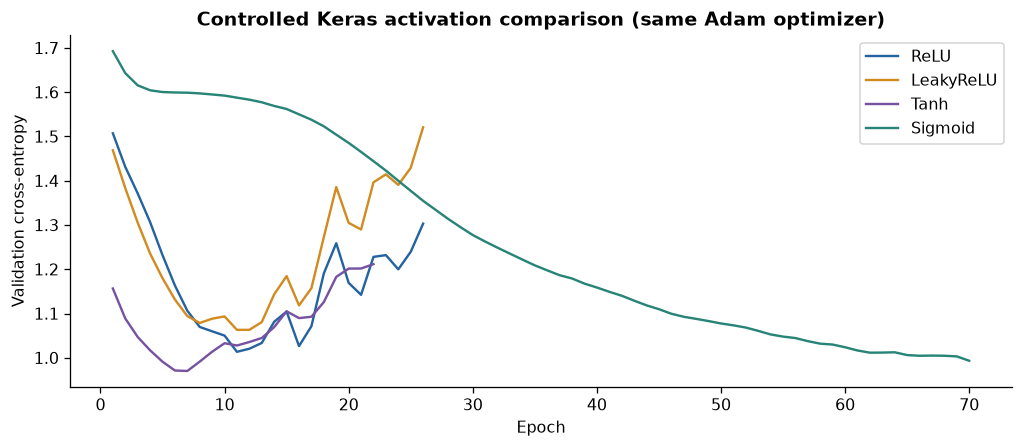

NN chosen activation (Tanh): test accuracy=0.500, macro F1=0.493
Validation-selected activation: Tanh | best epoch: 7
Activation selection used no held-out test labels.


**Observed comparison.** **Tanh** has the lowest validation
loss (0.970), at epoch
7. Validation loss is the prespecified selection
criterion; the highest validation accuracy can occur for a different activation.
ReLU retains positive gradients without saturating on its positive side; LeakyReLU
also preserves a small negative-side gradient, while tanh and sigmoid can saturate.
In this run, Sigmoid's best epoch is 70
out of a 70-epoch cap. If its curve is still improving at the cap, that is evidence
of slower optimization rather than proof of a worse attainable model. Different
activation families may need different training budgets; we keep the common budget
here for a transparent experiment.

In [36]:
# Change one activation family at a time, using the same training policy.
# Four matching Keras models: identical optimizer, widths, minibatches, max epochs and split.
# Validation loss, not held-out test performance, chooses the best epoch/activation.
activation_experiments, activation_histories = [], {}
activation_models = {}

def activation_network(activation_name):
    layers_list = [layers.Input(shape=(feature_count,))]
    for width in (128, 64, 64, 32):
        layers_list.append(layers.Dense(width))
        layers_list.append(layers.LeakyReLU(negative_slope=.1) if activation_name == 'LeakyReLU'
                           else layers.Activation(activation_name.lower()))
    layers_list.append(layers.Dense(n_classes, activation='softmax'))
    network = keras.Sequential(layers_list)
    network.compile(optimizer=keras.optimizers.Adam(learning_rate=.001),
                    loss='categorical_crossentropy', metrics=['accuracy'])
    return network

for activation_name in ('ReLU', 'LeakyReLU', 'Tanh', 'Sigmoid'):
    keras.utils.set_random_seed(SEED)
    act_model = activation_network(activation_name)
    # Restoring best validation weights ensures the *reported* epoch matches the model.
    callbacks = [keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=15, restore_best_weights=True)]
    act_history = act_model.fit(train_nn, y_train_oh.to_numpy(), batch_size=20,
                                epochs=70, validation_split=.25,
                                callbacks=callbacks, verbose=0).history
    best_idx = int(np.argmin(act_history['val_loss']))
    activation_models[activation_name] = act_model
    activation_experiments.append({
        'Activation': activation_name,
        'Best validation loss': float(act_history['val_loss'][best_idx]),
        'Best epoch': best_idx + 1,
        'Validation accuracy AT chosen epoch': float(act_history['val_accuracy'][best_idx]),
        'Epochs run': len(act_history['loss']),
    })
    activation_histories[activation_name] = act_history['val_loss']
activation_df = pd.DataFrame(activation_experiments).set_index('Activation')
display(activation_df.round(3))
fig, ax = plt.subplots(figsize=(9, 4))
for name, losses in activation_histories.items():
    ax.plot(np.arange(1, len(losses)+1), losses, label=name)
ax.set(xlabel='Epoch', ylabel='Validation cross-entropy',
       title='Controlled Keras activation comparison (same Adam optimizer)')
ax.legend(); plt.tight_layout(); plt.show()
best_activation = activation_df['Best validation loss'].idxmin()
# ONLY the validation-chosen model receives a new final test evaluation.
best_activation_probs = activation_models[best_activation].predict(test_nn, verbose=0)
act_scores = evaluate_classifier(f'NN chosen activation ({best_activation})', y_test_labels,
                 best_activation_probs.argmax(axis=1), show_report=False)
print('Validation-selected activation:', best_activation,
      '| best epoch:', activation_df.loc[best_activation,'Best epoch'])
print('Activation selection used no held-out test labels.')

activation_best_row = activation_df.loc[best_activation]
explain(f"""**Observed comparison.** **{best_activation}** has the lowest validation
loss ({activation_best_row['Best validation loss']:.3f}), at epoch
{int(activation_best_row['Best epoch'])}. Validation loss is the prespecified selection
criterion; the highest validation accuracy can occur for a different activation.
ReLU retains positive gradients without saturating on its positive side; LeakyReLU
also preserves a small negative-side gradient, while tanh and sigmoid can saturate.
In this run, Sigmoid's best epoch is {int(activation_df.loc['Sigmoid','Best epoch'])}
out of a 70-epoch cap. If its curve is still improving at the cap, that is evidence
of slower optimization rather than proof of a worse attainable model. Different
activation families may need different training budgets; we keep the common budget
here for a transparent experiment.""")

---

## 8. Explainability – SHAP Feature Importance

To better understand the model's predictions, we will use **SHAP (SHapley Additive exPlanations)** to analyze feature importance.

**How SHAP works:**

- SHAP assigns each feature a contribution score for every prediction.
- It uses Shapley values (from cooperative game theory) to fairly distribute importance across features.

We will apply SHAP to visualize and interpret the model's feature contributions.

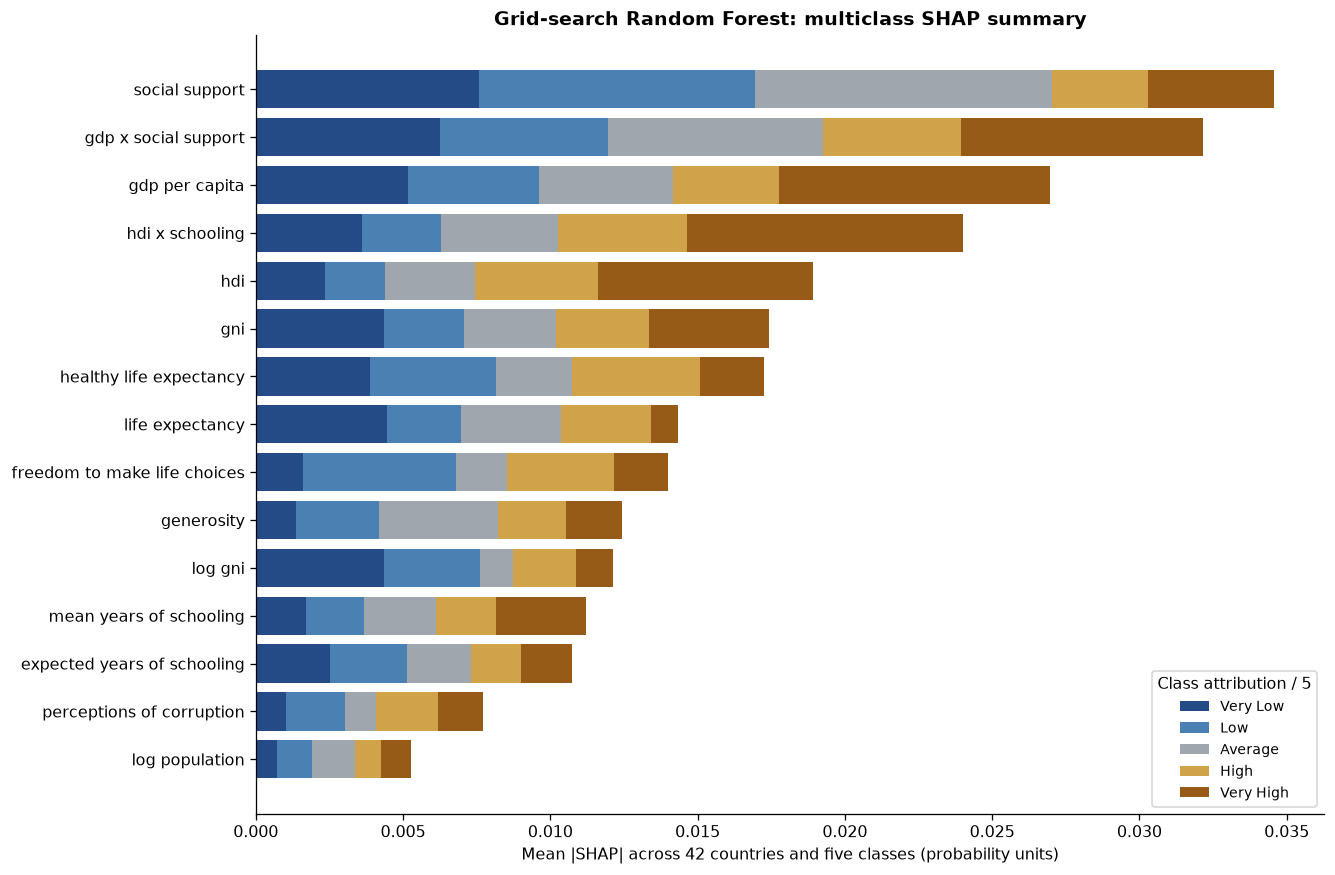

,Mean absolute Tree SHAP
num__social_support,0.0346
num__gdp_x_social_support,0.0322
num__gdp_per_capita,0.0270
num__hdi_x_schooling,0.0240
num__hdi,0.0189
num__gni,0.0174
num__healthy_life_expectancy,0.0173
num__life_expectancy,0.0143
num__freedom_to_make_life_choices,0.0140
num__generosity,0.0124


In [37]:
import warnings
# Static plots do not require the optional notebook progress widget.
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='IProgress not found.*')
    import shap
# Match the tree to the exact fitted transformer in its search pipeline.
tree_pipeline = gridmodel.best_estimator_
tree_preprocess_for_shap = tree_pipeline.named_steps['preprocess']
tree_model_for_shap = tree_pipeline.named_steps['classifier']
shap_feature_names = tree_preprocess_for_shap.get_feature_names_out().tolist()
shap_test = np.asarray(tree_preprocess_for_shap.transform(X_test), dtype=float)
tree_explainer = shap.TreeExplainer(tree_model_for_shap)
shap_values = tree_explainer(shap_test)
assert shap_values.values.shape == (len(X_test),len(shap_feature_names),n_classes)
mean_abs_shap = np.abs(shap_values.values).mean(axis=(0,2))
shap_rank = pd.Series(mean_abs_shap,index=shap_feature_names,name='Mean absolute Tree SHAP').sort_values(ascending=False)
# Stacked summary: class contributions divided by five, so bar totals equal mean |SHAP|.
per_class = np.abs(shap_values.values).mean(axis=0) / n_classes
selected = np.argsort(mean_abs_shap)[-15:]
fig, ax = plt.subplots(figsize=(11.5, 7.5), layout='constrained')
left = np.zeros(len(selected))
colors = ['#254B87','#4A80B2','#A0A6AE','#D0A34A','#965C17']
for k, label in enumerate(CLASS_NAMES):
    widths = per_class[selected,k]
    ax.barh(np.arange(len(selected)), widths, left=left, label=label, color=colors[k])
    left += widths
ax.set_yticks(np.arange(len(selected)),[shap_feature_names[j].replace('num__','').replace('cat__','').replace('_',' ') for j in selected])
ax.set(xlabel='Mean |SHAP| across 42 countries and five classes (probability units)',
       title='Grid-search Random Forest: multiclass SHAP summary')
ax.legend(title='Class attribution / 5',loc='lower right',fontsize=9)
plt.show()
display(shap_rank.head(12).round(4).to_frame())

Random Forest SHAP: grouped original indicators, all test countries and classes


,Feature group,Mean |SHAP|
27,social_support,0.0346
3,gdp_x_social_support,0.0322
2,gdp_per_capita,0.0270
7,hdi_x_schooling,0.0240
6,hdi,0.0189
26,region (all one-hot levels),0.0183
5,gni,0.0174
8,healthy_life_expectancy,0.0173
9,life_expectancy,0.0143
1,freedom_to_make_life_choices,0.0140


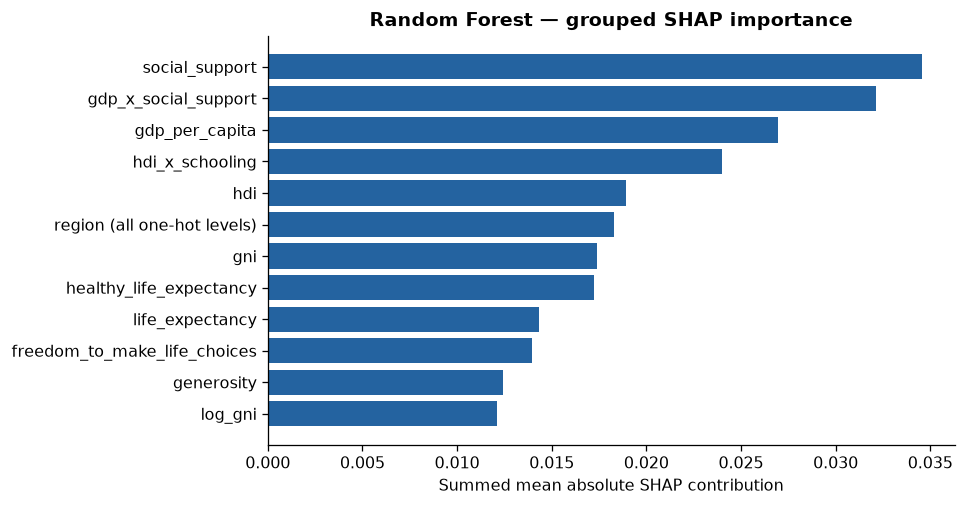

In [38]:
# Aggregate categorical region one-hot columns for more interpretable Tree SHAP.
# Mean |SHAP| is aggregated by original feature family; interactions remain separate.
def attribution_group(processed_name):
    if processed_name.startswith('cat__region_'): return 'region (all one-hot levels)'
    if processed_name.startswith('num__missingindicator_'):
        return processed_name.replace('num__missingindicator_', 'missing: ')
    return processed_name.replace('num__', '').replace('cat__', '')
raw_shap_importance = (pd.DataFrame({'Feature group':
    [attribution_group(name) for name in shap_feature_names],
    'Mean |SHAP|': mean_abs_shap})
    .groupby('Feature group', as_index=False)['Mean |SHAP|'].sum()
    .sort_values('Mean |SHAP|', ascending=False))
print('Random Forest SHAP: grouped original indicators, all test countries and classes')
display(raw_shap_importance.head(12).round(4))
fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_data = raw_shap_importance.head(12).iloc[::-1]
ax.barh(plot_data['Feature group'], plot_data['Mean |SHAP|'])
ax.set(xlabel='Summed mean absolute SHAP contribution',
       title='Random Forest — grouped SHAP importance')
plt.tight_layout(); plt.show()


### Explaining the Deep Learning Model

Deep learning models are often considered "black boxes" due to their complexity. Use SHAP to explain your model's predictions.

After applying SHAP, discuss:

- Does it provide a clear and sufficient explanation of how the model makes decisions?
- How easy or difficult is it to justify your model's predictions using this technique?

Explained NN: Dropout + BatchNorm (Adam) | foreground: 12 | background: 15


,Mean absolute NN SHAP
num__social_support,0.0432
num__freedom_to_make_life_choices,0.0325
num__log_gni,0.0284
num__gni,0.0270
num__gdp_x_social_support,0.0265
num__gdp_per_capita,0.0222
num__hdi_x_schooling,0.0210
num__population_below_poverty_line,0.0197
num__expected_years_of_schooling,0.0196
num__mean_years_of_schooling,0.0186


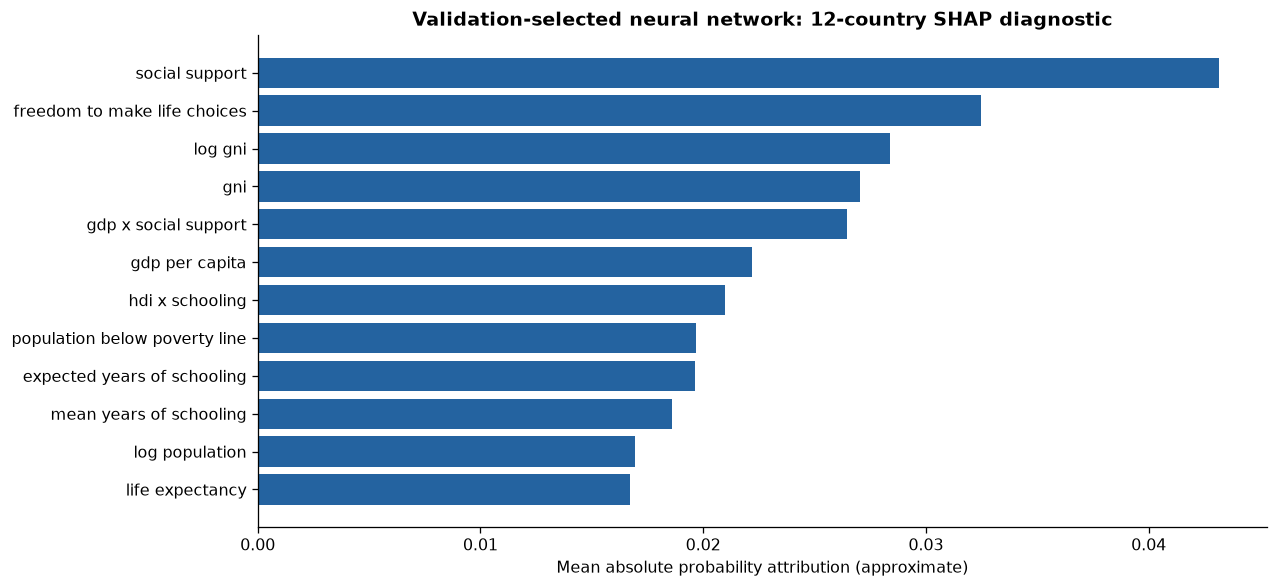

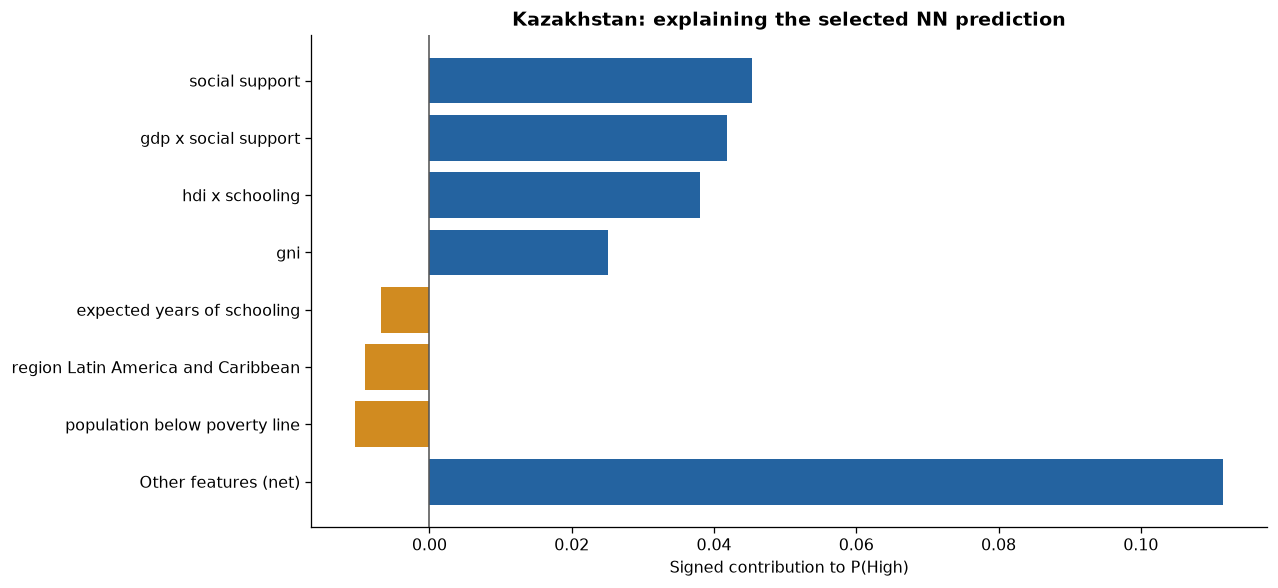

For **Kazakhstan**, the network predicts **High**;
the observed class is **High**. Its predicted-class
probability is **0.373**, compared with a background probability
of **0.137**. Signed contributions sum to **+0.236**,
reconstructing **0.373**. The largest upward/downward contributions
are **social_support** (+0.0453) and **population_below_poverty_line**
(-0.0105), respectively. Positive bars increase this
particular class probability; they do not necessarily imply higher happiness in general.
The example is the first test row, chosen before inspecting SHAP values.

In [39]:
# Explain the validation-selected regularization model, not an unrelated baseline.
import warnings
nn_explained_model = control_models[chosen_variant]
nn_shap_names = nn_preprocess.get_feature_names_out().tolist()
nn_background = shap.sample(train_nn[:nn_split_at], 15, random_state=SEED)
nn_foreground = test_nn[:12]  # Fixed first 12 shuffled test rows, not selected for explanation quality.
np.random.seed(SEED)
kernel_explainer = shap.KernelExplainer(
    lambda z: nn_explained_model.predict(np.asarray(z,dtype='float32'),verbose=0),
    nn_background)
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=FutureWarning)
    deep_shap_values = kernel_explainer.shap_values(nn_foreground, nsamples=300,
                                                  l1_reg=0, silent=True)
deep_shap_array = np.stack(deep_shap_values,axis=-1) if isinstance(deep_shap_values,list) else np.asarray(deep_shap_values)
assert deep_shap_array.shape == (len(nn_foreground),len(nn_shap_names),n_classes)
nn_importance = pd.Series(np.abs(deep_shap_array).mean(axis=(0,2)),
                          index=nn_shap_names,name='Mean absolute NN SHAP')
print('Explained NN:', chosen_variant, '| foreground:',len(nn_foreground),'| background:',len(nn_background))
display(nn_importance.sort_values(ascending=False).head(12).round(4).to_frame())
fig, ax = plt.subplots(figsize=(11,5),layout='constrained')
ranked_nn = nn_importance.sort_values().tail(12)
ax.barh([s.replace('num__','').replace('cat__','').replace('_',' ') for s in ranked_nn.index],ranked_nn.values)
ax.set(xlabel='Mean absolute probability attribution (approximate)',
       title='Validation-selected neural network: 12-country SHAP diagnostic')
plt.show()

# One prespecified country and its predicted class: signed attributions sum to probability.
local_country = X_test.iloc[0]['country']
local_probs = nn_explained_model.predict(nn_foreground[:1],verbose=0)[0]
local_class = int(local_probs.argmax())
local_values = deep_shap_array[0,:,local_class]
local_base = float(np.asarray(kernel_explainer.expected_value)[local_class])
local_reconstruction = local_base + local_values.sum()
assert np.isclose(local_reconstruction,local_probs[local_class],atol=1e-4)
positive = np.flatnonzero(local_values > 0)
negative = np.flatnonzero(local_values < 0)
selected_local = np.r_[positive[np.argsort(local_values[positive])[-4:]],
                        negative[np.argsort(local_values[negative])[:4]]]
order = selected_local[np.argsort(local_values[selected_local])]
labels = [nn_shap_names[j].replace('num__','').replace('cat__','').replace('_',' ') for j in order]
values = local_values[order]
other = float(local_values.sum()-values.sum())
labels = ['Other features (net)'] + labels
values = np.r_[other,values]
fig, ax = plt.subplots(figsize=(11,5),layout='constrained')
ax.barh(labels,values,color=['#2463A0' if v>=0 else '#D18B20' for v in values])
ax.axvline(0,color='#555555',linewidth=1)
ax.set(xlabel=f'Signed contribution to P({CLASS_NAMES[local_class]})',
       title=f'{local_country}: explaining the selected NN prediction')
plt.show()
local_top_positive = nn_shap_names[int(np.argmax(local_values))].replace('num__','').replace('cat__','')
local_top_negative = nn_shap_names[int(np.argmin(local_values))].replace('num__','').replace('cat__','')
explain(f"""For **{local_country}**, the network predicts **{CLASS_NAMES[local_class]}**;
the observed class is **{CLASS_NAMES[int(y_test_labels.iloc[0])]}**. Its predicted-class
probability is **{local_probs[local_class]:.3f}**, compared with a background probability
of **{local_base:.3f}**. Signed contributions sum to **{local_values.sum():+.3f}**,
reconstructing **{local_reconstruction:.3f}**. The largest upward/downward contributions
are **{local_top_positive}** ({local_values.max():+.4f}) and **{local_top_negative}**
({local_values.min():+.4f}), respectively. Positive bars increase this
particular class probability; they do not necessarily imply higher happiness in general.
The example is the first test row, chosen before inspecting SHAP values.""")

**Does SHAP give a clear and sufficient explanation?** It gives a useful, model-specific
account of which inputs change a predicted probability relative to a background.
The signed country example makes that account more concrete than a global importance
ranking. It is **not sufficient** to describe the network's entire decision mechanism,
prove the prediction is correct, or justify an intervention on national happiness.

**How difficult is it to justify a prediction?** We can explain its direction and
magnitude relative to the chosen background, and check the probability reconstruction.
However, Kernel SHAP is approximate (12 foreground countries, 15 background countries,
300 sampled coalitions). Correlated GDP, HDI, GNI and schooling, deterministic interaction
features, and background choice can redistribute attributions or create implausible
feature combinations. A larger/alternative background and repeated estimates would
check stability. This local explanation is evidence about a fitted model, not a causal
explanation of a country's happiness.

Tree SHAP summarizes all 42 test countries for the CV-tuned RF. The neural explanation
uses the validation-selected regularization model. Their populations and models differ,
so their numerical attribution rankings should not be treated as a controlled comparison.
The grouped region display sums absolute contributions over dummy columns; it is a
measure of total encoded-feature activity, not the absolute value of a single signed
region effect. The WHR factor columns are score-contribution proxies; the next sensitivity
analysis checks performance without them, using training folds only.

### Experimentation

In [40]:
# Stability and feature sensitivity, using training data only.
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
majority_model = DummyClassifier(strategy='most_frequent').fit(X_train_processed, y_train_labels)
majority_scores = evaluate_classifier('Dummy majority baseline', y_test_labels,
                                      majority_model.predict(X_test_processed),
                                      show_report=False)
print('Five balanced labels have an approximately 20% chance-level accuracy baseline.')

# Repeated CV on TRAINING COUNTRIES ONLY; each pipeline refits preprocessing INSIDE each fold.
# Paired folds allow a fair comparison of the same input countries across models.
repeat_cv = list(RepeatedStratifiedKFold(
    n_splits=4, n_repeats=3, random_state=SEED).split(X_train, y_train_labels))
repeat_rows, repeated_fold_scores = [], {}
for candidate_name, classifier in cv_candidates.items():
    fold_pipeline = Pipeline([('preprocess', clone(preprocess)),
                              ('classifier', clone(classifier))])
    scores = cross_val_score(fold_pipeline, X_train, y_train_labels,
                             scoring='f1_macro', cv=repeat_cv, n_jobs=1)
    repeated_fold_scores[candidate_name] = scores
    repeat_rows.append({'Model': candidate_name, 'Mean CV macro F1': scores.mean(),
                        'SD across folds': scores.std(ddof=1),
                        'Minimum': scores.min(), 'Maximum': scores.max(),
                        'Fold scores': len(scores)})
repeat_table = (pd.DataFrame(repeat_rows).sort_values('Mean CV macro F1',
                      ascending=False).reset_index(drop=True))
print('Training-only repeated 4-fold CV × 3 repeats (not independent confidence intervals):')
display(repeat_table.round(3))

# Paired sensitivity experiment for potentially target-proximal WHR columns.
whr_contribution_cols = ['gdp_per_capita', 'social_support', 'healthy_life_expectancy',
    'freedom_to_make_life_choices', 'generosity', 'perceptions_of_corruption',
    'gdp_x_social_support']
X_train_dev_only = X_train.drop(columns=whr_contribution_cols)
dev_numeric = X_train_dev_only.select_dtypes(include='number').columns.tolist()
dev_preprocess = ColumnTransformer([
    ('num', clone(numeric_transformer), dev_numeric),
    ('cat', clone(categorical_transformer), ['region']),
], remainder='drop', sparse_threshold=0)
svc_all = Pipeline([('preprocess', clone(preprocess)),
                    ('classifier', SVC(kernel='rbf', C=2., gamma='scale'))])
dev_only_svc = Pipeline([('preprocess', dev_preprocess),
                         ('classifier', SVC(kernel='rbf', C=2., gamma='scale'))])
all_feature_scores = cross_val_score(svc_all, X_train, y_train_labels,
                      scoring='f1_macro', cv=repeat_cv, n_jobs=1)
dev_only_scores = cross_val_score(dev_only_svc, X_train_dev_only, y_train_labels,
                      scoring='f1_macro', cv=repeat_cv, n_jobs=1)
paired_delta = all_feature_scores - dev_only_scores
ablation_table = pd.DataFrame({
    'Feature set': ['All available predictors', 'Exclude WHR contribution proxies'],
    'Mean CV macro F1': [all_feature_scores.mean(), dev_only_scores.mean()],
    'SD across folds': [all_feature_scores.std(ddof=1), dev_only_scores.std(ddof=1)],
    'Number of fold scores': [len(all_feature_scores)] * 2,
})
print('Same training folds for both SVC feature sets:')
display(ablation_table.round(3))
print('Paired mean (all minus excluded): {:.3f}; paired SD: {:.3f}'.format(
    paired_delta.mean(), paired_delta.std(ddof=1)))
print('These overlapping repeated-CV fold results are descriptive, not an independent CI;'
      ' removing score-proxy inputs is a robustness check, not a causal test.')

explain(f"""**Robustness findings.** The repeated four-fold CV leader among the
prespecified classical models is **{repeat_table.iloc[0]['Model']}**, with mean macro
F1 **{repeat_table.iloc[0]['Mean CV macro F1']:.3f}** and across-fold SD
**{repeat_table.iloc[0]['SD across folds']:.3f}**. In the paired SVC feature comparison,
mean macro F1 is **{all_feature_scores.mean():.3f}** with all predictors versus
**{dev_only_scores.mean():.3f}** without the WHR contribution proxies; the difference
is **{paired_delta.mean():+.3f}**, compared with paired fold SD **{paired_delta.std(ddof=1):.3f}**.
The feature ablation changes the available information and SVC geometry together, so
it is a sensitivity check, not proof of leakage or causality. Fold scores overlap in
training observations; the reported SD is descriptive, not a confidence interval.""")

Dummy majority baseline: test accuracy=0.214, macro F1=0.071
Five balanced labels have an approximately 20% chance-level accuracy baseline.


Training-only repeated 4-fold CV × 3 repeats (not independent confidence intervals):


,Model,Mean CV macro F1,SD across folds,Minimum,Maximum,Fold scores
0,RF baseline,0.529,0.095,0.340,0.651,12
1,RF manually tuned,0.506,0.072,0.409,0.618,12
2,KNN (k=7),0.487,0.078,0.373,0.595,12
3,SVC (RBF),0.486,0.060,0.359,0.581,12


Same training folds for both SVC feature sets:


,Feature set,Mean CV macro F1,SD across folds,Number of fold scores
0,All available predictors,0.486,0.060,12
1,Exclude WHR contribution proxies,0.470,0.085,12


Paired mean (all minus excluded): 0.016; paired SD: 0.085
These overlapping repeated-CV fold results are descriptive, not an independent CI; removing score-proxy inputs is a robustness check, not a causal test.


**Robustness findings.** The repeated four-fold CV leader among the
prespecified classical models is **RF baseline**, with mean macro
F1 **0.529** and across-fold SD
**0.095**. In the paired SVC feature comparison,
mean macro F1 is **0.486** with all predictors versus
**0.470** without the WHR contribution proxies; the difference
is **+0.016**, compared with paired fold SD **0.085**.
The feature ablation changes the available information and SVC geometry together, so
it is a sensitivity check, not proof of leakage or causality. Fold scores overlap in
training observations; the reported SD is descriptive, not a confidence interval.

---

## 9. Final Summary

Summarize your project in a few short paragraphs. Include:

- A table comparing the test performance of every model you trained
- Your best-performing model, its hyperparameters, and why you think it performed best
- The most important insights from your EDA and SHAP analysis
- Limitations of your approach and what you would try next

### Final comparison and conclusions

All model choices are now fixed. The table below adds the previously unreported
neural variants, so it covers each fitted experimental configuration. ReLU in the
activation experiment repeats the unregularized Adam architecture from the ablation;
those two rows are retained for experiment completeness and are **not independent
confirmation**. Cross-validation fold fits and grid-search candidates are summarized
by their training-validation tables rather than treated as separate final models.

The following conclusions are generated from this run's results. Neither a test-table
rank nor a test confidence interval is used to change any model or parameter.

In [41]:
# Complete final test reporting AFTER the validation choices are fixed.
for variant_name, fitted_net in control_models.items():
    if variant_name != chosen_variant:
        evaluate_classifier(f'NN ablation ({variant_name})',y_test_labels,
            fitted_net.predict(test_nn,verbose=0).argmax(axis=1),show_report=False)
for activation_name, fitted_net in activation_models.items():
    if activation_name != best_activation:
        evaluate_classifier(f'NN activation ({activation_name})',y_test_labels,
            fitted_net.predict(test_nn,verbose=0).argmax(axis=1),show_report=False)
assert len(model_results) == 16 and len(prediction_registry) == 16
comparison = pd.DataFrame(model_results).sort_values(
    ['Test macro F1','Test accuracy'],ascending=False).reset_index(drop=True)
# Readable aliases keep the complete table narrow.
def readable_model(name):
    name = name.replace('NN validation-selected (','NN ablation: ').replace('NN ablation (','NN ablation: ')
    name = name.replace('NN chosen activation (','NN activation: ').replace('NN activation (','NN activation: ')
    return (name.rstrip(')').replace(' (Adam','').replace('No regularization','None')
            if name.startswith(('NN ablation:', 'NN activation:')) else name)
comparison['Experiment'] = comparison['Model'].map(readable_model)
comparison['Correct / 42'] = [f"{int(np.sum(prediction_registry[m]==y_test_labels.to_numpy()))}/42" for m in comparison['Model']]
display(comparison[['Experiment','Correct / 42','Test accuracy','Test macro F1']].round(3))

NN ablation (No regularization (Adam)): test accuracy=0.524, macro F1=0.524


NN ablation (Dropout only (Adam)): test accuracy=0.643, macro F1=0.638
NN ablation (BatchNorm only (Adam)): test accuracy=0.500, macro F1=0.457
NN activation (ReLU): test accuracy=0.524, macro F1=0.524
NN activation (LeakyReLU): test accuracy=0.571, macro F1=0.565
NN activation (Sigmoid): test accuracy=0.548, macro F1=0.470


,Experiment,Correct / 42,Test accuracy,Test macro F1
0,NN ablation: Dropout only,27/42,0.643,0.638
1,SVC (RBF),25/42,0.595,0.596
2,KNN (k=7),24/42,0.571,0.576
3,RF manually tuned,24/42,0.571,0.574
4,NN activation: LeakyReLU,24/42,0.571,0.565
5,NN ablation: Dropout + BatchNorm,24/42,0.571,0.564
6,NN dropout + batch norm,24/42,0.571,0.563
7,RF baseline,23/42,0.548,0.548
8,NN ablation: None,22/42,0.524,0.524
9,NN activation: ReLU,22/42,0.524,0.524


Parameters of the strongest observed test model:


,Value
Dense widths,128 → 64 → 64 → 32 → 5
output,softmax
loss,categorical_crossentropy
batch_size,20
optimizer,"Adam, learning_rate=0.001"
activation,ReLU
Dropout,0.20 after first three hidden layers
BatchNorm,none
best_epoch,24
patience,15


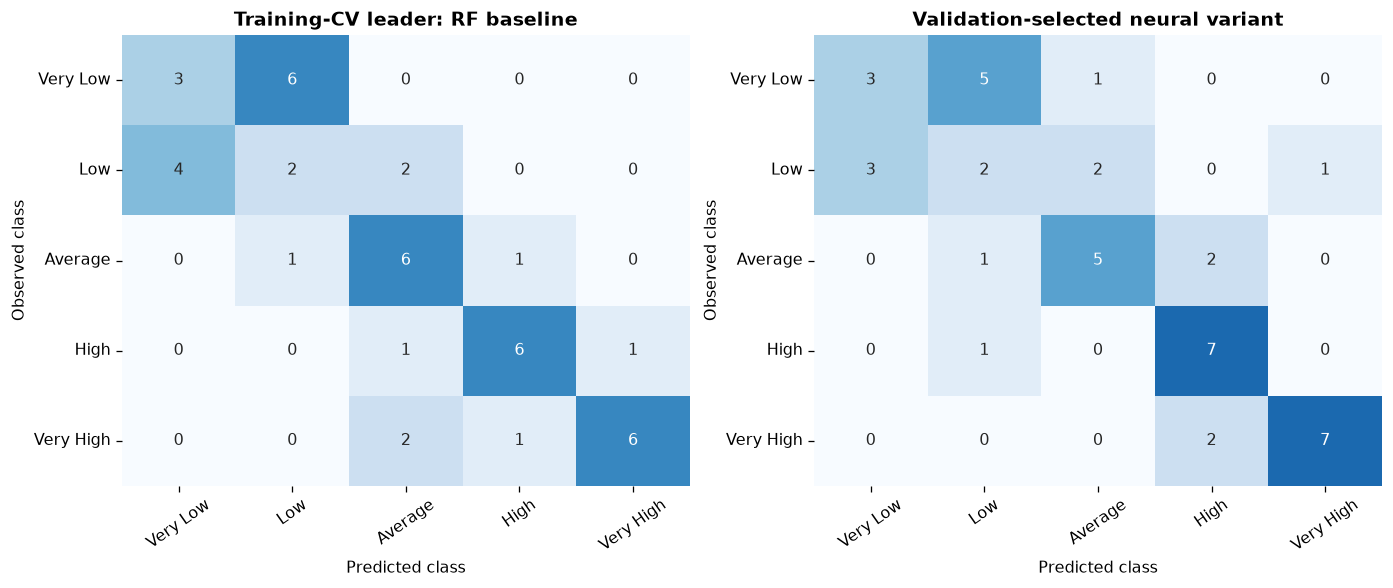

**Error diagnosis.** For the validation-selected neural model, the largest
single off-diagonal cell is **Very Low → Low**
(5 countries). The five labels discretize a continuous score,
so neighboring-class mistakes and very-low-versus-very-high mistakes should not be
interpreted identically, although ordinary accuracy counts them equally. An ordinal
model or ordinal error measure would be a useful follow-up; the required multiclass
metrics remain the primary reporting metrics here.

In [42]:
best_name = comparison.iloc[0]['Model']
best_observed = comparison.iloc[0]
# Describe actual trained configurations, not a manually typed winning configuration.
classical_objects = {'RF baseline':rf_baseline,'RF manually tuned':model_2,
    'RF grid search':tree_model_for_shap,'SVC (RBF)':svc_model,'KNN (k=7)':knn_model}
if best_name in classical_objects:
    obj=classical_objects[best_name]
    relevant = (['n_estimators','max_depth','min_samples_leaf','max_features','random_state']
                if 'RF' in best_name else ['C','kernel','gamma'] if 'SVC' in best_name
                else ['n_neighbors','weights','p'])
    best_parameters = {k:obj.get_params()[k] for k in relevant}
    reason = ('Tree averaging can capture nonlinear thresholds and interactions.' if 'RF' in best_name
              else 'An RBF kernel can capture nonlinear similarities after scaling.' if 'SVC' in best_name
              else 'Distance weighting combines information from nearby standardized country profiles.')
else:
    best_parameters = {'Dense widths':'128 → 64 → 64 → 32 → 5','output':'softmax',
                      'loss':'categorical_crossentropy','batch_size':20}
    if best_name=='NN base (SGD, 300 epochs)':
        best_parameters.update({'optimizer':'SGD, learning_rate=0.01','activation':'ReLU','epochs':300})
    elif best_name=='NN dropout + batch norm':
        best_parameters.update({'optimizer':'Adam, learning_rate=0.001','activation':'ReLU',
          'dropout':'0.25, 0.25, 0.15','BatchNorm':'first two hidden layers',
          'best_epoch':int(np.argmin(regularized_history.history['val_loss']))+1,'patience':18})
    elif 'activation' in best_name.lower():
        key=next(a for a in activation_models if f'({a})' in best_name)
        best_parameters.update({'optimizer':'Adam, learning_rate=0.001','activation':key,
           'best_epoch':int(activation_df.loc[key,'Best epoch']),'patience':15,'max_epochs':70})
    else:
        key=next(v for v in control_models if f'({v})' in best_name)
        drop,bn=regularization_configs[key]
        best_parameters.update({'optimizer':'Adam, learning_rate=0.001','activation':'ReLU',
            'Dropout':'0.20 after first three hidden layers' if drop else 'none',
            'BatchNorm':'all four hidden layers' if bn else 'none',
            'best_epoch':int(controlled_df.loc[key,'Best epoch']),'patience':15,'max_epochs':100})
    reason='The network can learn nonlinear combinations, while its training policy controls optimization and overfitting.'
print('Parameters of the strongest observed test model:')
display(pd.Series(best_parameters,name='Value').to_frame())

# Confusion matrices for validation-selected candidates, not post-test winners.
fig, axes = plt.subplots(1,2,figsize=(12,5),layout='constrained')
selected_nn_name = f'NN validation-selected ({chosen_variant})'
for ax, name, title in zip(axes, ['RF baseline',selected_nn_name],
                          ['Training-CV leader: RF baseline','Validation-selected neural variant']):
    matrix=confusion_matrix(y_test_labels,prediction_registry[name],labels=np.arange(5))
    sns.heatmap(matrix,annot=True,fmt='d',cmap='Blues',vmin=0,vmax=9,
                xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,cbar=False,ax=ax)
    ax.set(title=title,xlabel='Predicted class',ylabel='Observed class')
    ax.tick_params(axis='x',rotation=35)
    ax.tick_params(axis='y',rotation=0)
plt.show()
selected_cm=confusion_matrix(y_test_labels,prediction_registry[selected_nn_name],labels=np.arange(5))
offdiag=selected_cm.copy(); np.fill_diagonal(offdiag,0)
error_i,error_j=np.unravel_index(np.argmax(offdiag),offdiag.shape)
explain(f"""**Error diagnosis.** For the validation-selected neural model, the largest
single off-diagonal cell is **{CLASS_NAMES[error_i]} → {CLASS_NAMES[error_j]}**
({offdiag[error_i,error_j]} countries). The five labels discretize a continuous score,
so neighboring-class mistakes and very-low-versus-very-high mistakes should not be
interpreted identically, although ordinary accuracy counts them equally. An ordinal
model or ordinal error measure would be a useful follow-up; the required multiclass
metrics remain the primary reporting metrics here.""")

In [43]:
# Wilson interval describes uncertainty for a fixed classifier under a binomial model.
# It is not a post-selection-adjusted interval or evidence that a model beats another.
from math import sqrt
count=int(np.sum(prediction_registry[best_name]==y_test_labels.to_numpy()))
N=len(y_test); phat=count/N; z=1.959963984540054
center=(phat+z*z/(2*N))/(1+z*z/N)
half=z*sqrt(phat*(1-phat)/N+z*z/(4*N*N))/(1+z*z/N)
rf_top = ', '.join(raw_shap_importance.head(3)['Feature group'])
nn_top = ', '.join(nn_importance.sort_values(ascending=False).head(3).index.str.replace('num__','',regex=False))
explain(f"""### Findings from this run

**Performance.** The largest observed test macro F1 is **{best_observed['Test macro F1']:.3f}**
for **{readable_model(best_name)}**, with accuracy **{best_observed['Test accuracy']:.3f}**
({count}/42); its actual hyperparameters are listed above. {reason} This is a plausible
mechanism, not evidence that the model family is intrinsically best. A descriptive 95%
Wilson interval for that accuracy is **[{center-half:.3f}, {center+half:.3f}]**, assuming
independent test outcomes for a fixed classifier. Country dependence and selecting the
best row after seeing test scores weaken that interpretation; the interval is not
selection-adjusted and does not test differences between models.

**Selection versus reporting.** Training-only repeated CV favors
**{repeat_table.iloc[0]['Model']}** among prespecified classical candidates
(mean macro F1 {repeat_table.iloc[0]['Mean CV macro F1']:.3f}); neural validation selects
**{chosen_variant}** for regularization and **{best_activation}** for activation.
The 4-fold classical scores and 24-country neural validation losses use different
validation designs and are not a fair model-family contest. We would use a common
nested/repeated training-validation design before choosing a deployment model.
One additional correct test country changes accuracy by **{100/N:.2f} percentage points**.

**EDA.** GDP contribution and social support are strongly associated with ordered
happiness classes (training Spearman correlations **{association['gdp_per_capita']:.3f}**
and **{association['social_support']:.3f}**). Population and GNI are right-skewed, motivating
log features. Poverty is missing for **{int(missing_summary.loc['population_below_poverty_line','missing_n'])}/95**
training countries. We retained plausible outliers and used training-derived imputation.
HDI, schooling and life expectancy are strongly correlated, which complicates attribution.

**SHAP.** The leading grouped tree predictors are **{rf_top}**. For the selected neural
model on the fixed 12-country subset, the leading approximate predictors are **{nn_top}**.
The local {local_country} example explains a class probability relative to a background;
it does not establish that changing a predictor would change national happiness.
These rankings depend on the model, correlated inputs and explanation population.

**Limitations and next steps.** There are only 137 countries; the external indicators
are older than the 2020–2022 happiness surveys. Missingness, redundant predictors,
WHR score-contribution proxies and quintile discretization constrain external validity.
Neural weights use 71 fitting countries, versus 95 for the final classical fits.
Next, compare a smaller network and multiple prespecified seeds/internal splits using
training data only; use nested validation to compare full model-selection procedures;
and test SHAP stability across backgrounds. The paired SVC feature ablation changes
mean training CV macro F1 by **{paired_delta.mean():+.3f}** when WHR proxies are included,
so its small average difference should not be overinterpreted.

**Submission.** Canvas receives this saved `Project_1.ipynb`. GitHub receives the same
file at `Project_1/Project_1.ipynb` and both original CSVs in `Project_1/data/`. Fill the
UNI fields and actual public repository URL in the opening cell before submission.
""")

### Findings from this run

**Performance.** The largest observed test macro F1 is **0.638**
for **NN ablation: Dropout only**, with accuracy **0.643**
(27/42); its actual hyperparameters are listed above. The network can learn nonlinear combinations, while its training policy controls optimization and overfitting. This is a plausible
mechanism, not evidence that the model family is intrinsically best. A descriptive 95%
Wilson interval for that accuracy is **[0.492, 0.770]**, assuming
independent test outcomes for a fixed classifier. Country dependence and selecting the
best row after seeing test scores weaken that interpretation; the interval is not
selection-adjusted and does not test differences between models.

**Selection versus reporting.** Training-only repeated CV favors
**RF baseline** among prespecified classical candidates
(mean macro F1 0.529); neural validation selects
**Dropout + BatchNorm (Adam)** for regularization and **Tanh** for activation.
The 4-fold classical scores and 24-country neural validation losses use different
validation designs and are not a fair model-family contest. We would use a common
nested/repeated training-validation design before choosing a deployment model.
One additional correct test country changes accuracy by **2.38 percentage points**.

**EDA.** GDP contribution and social support are strongly associated with ordered
happiness classes (training Spearman correlations **0.841**
and **0.836**). Population and GNI are right-skewed, motivating
log features. Poverty is missing for **11/95**
training countries. We retained plausible outliers and used training-derived imputation.
HDI, schooling and life expectancy are strongly correlated, which complicates attribution.

**SHAP.** The leading grouped tree predictors are **social_support, gdp_x_social_support, gdp_per_capita**. For the selected neural
model on the fixed 12-country subset, the leading approximate predictors are **social_support, freedom_to_make_life_choices, log_gni**.
The local Kazakhstan example explains a class probability relative to a background;
it does not establish that changing a predictor would change national happiness.
These rankings depend on the model, correlated inputs and explanation population.

**Limitations and next steps.** There are only 137 countries; the external indicators
are older than the 2020–2022 happiness surveys. Missingness, redundant predictors,
WHR score-contribution proxies and quintile discretization constrain external validity.
Neural weights use 71 fitting countries, versus 95 for the final classical fits.
Next, compare a smaller network and multiple prespecified seeds/internal splits using
training data only; use nested validation to compare full model-selection procedures;
and test SHAP stability across backgrounds. The paired SVC feature ablation changes
mean training CV macro F1 by **+0.016** when WHR proxies are included,
so its small average difference should not be overinterpreted.

**Submission.** Canvas receives this saved `Project_1.ipynb`. GitHub receives the same
file at `Project_1/Project_1.ipynb` and both original CSVs in `Project_1/data/`. Fill the
UNI fields and actual public repository URL in the opening cell before submission.


### Sources and software references

Data and assignment scaffold: instructor-supplied `WHR_2023.csv`, `newcountryvars.csv`, and `Project_1.ipynb`.
The WHR score is used only to construct the supplied quintile target; the six WHR factors are explanatory score contributions, not raw units.

- [scikit-learn: preprocessing, pipelines, and leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [Keras: model training and validation split](https://keras.io/api/models/model_training_apis/)
- [Keras: supported backends](https://keras.io/getting_started/)
- [SHAP: KernelExplainer](https://shap.readthedocs.io/en/stable/generated/shap.KernelExplainer.html)

The environment table records the installed versions used for the saved run. No additional country dataset or unverified lecture handout is used.
